# DataVerso 002 · Brazilian first names in Censo 2022

IBGE's *Nomes no Brasil* counts the first names of the people living in Brazil on 1 August 2022, the reference date of Censo Demográfico 2022, for the whole country, by sex and by birth decade. The [project notes](README.md) describe the data, their provenance and IBGE's counting rules; `build.py` turns IBGE's API responses into the tables read here.

The notebook first audits what the tables cover, then asks five questions:

1. How concentrated were first names in each birth decade?
2. Which names mark a generation?
3. How did Maria, Ana, João and José move across the decades?
4. How often do a few spelling patterns appear, and in which decades?
5. Which life cycles do names follow, and do some come back?

Every share uses the people listed in the relevant table as its denominator, for the reasons given in section 3.2.

## 1. Setup

Install this project environment with `uv sync --project projects/002-nomes-brasil` from the repository root, and select its `.venv/bin/python` as the notebook kernel. The notebook reads `data/processed/` and writes its results tables to `results/` and its figures to `figures/`, all beside it. The plots in sections 4 to 7 are drafts for reading the shapes. Section 9 draws the published figures from the results tables, each in Brazilian Portuguese and in English, in the house style of `house_style.py`, which registers the IBM Plex fonts kept in the repository's `fonts/` directory.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator
from scipy.interpolate import PchipInterpolator
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

from house_style import (
    ACCENT,
    AXIS,
    GROUP_COLOURS,
    INK,
    MEN,
    MUTED,
    PAPER,
    RC_PARAMS,
    RULE,
    SOCIAL_DPI,
    SOCIAL_SIZE,
    TITLE_FONT,
    frame,
    register_fonts,
    shade,
    tint,
)

In [2]:
PROCESSED_DIR = Path("data/processed")
RESULTS_DIR = Path("results")

# Census reference date: 1 August 2022
REFERENCE_YEAR = 2022
FIRST_DECADE, LAST_DECADE = 1930, 2020  # IBGE's oldest and youngest birth-decade labels

# Sections 4 and 6: the four most common first names in the national table
HEADS = ["maria", "ana", "joao", "jose"]

# Section 4.1: IBGE lists a name in a decade only when at least this many people bear it
DISCLOSURE_THRESHOLD = 20

# Sections 3.3 and 7: a name belongs to a sex class when at least this share of its bearers
# is of that sex
SEX_CLASS_THRESHOLD = 0.95

# Section 5: distinctive names
DISTINCTIVE_MIN_SHARE = 0.0005  # 1 in 2,000 listed people of the decade
DISTINCTIVE_TOP = 20  # names kept per decade
SMOOTHING = 0.5  # added to the pooled count and to the pooled total of the other decades

# Section 7: spelling patterns, matched with re.search on IBGE's lower-case form
SPELLING_PATTERNS = {
    "kwy": r"[kwy]",
    "th": r"th",
    "double_consonant": r"(bb|dd|ff|gg|ll|mm|nn|pp|tt|zz)",
    "son_ending": r"son$",
    "ton_ending": r"ton$",
}

# Sections 4.3, 5.1 and 8: figure tables
TOP_NAMES = 10
GENERATION_NAMES = 4
LIFE_CYCLE_K = 6
LIFE_CYCLE_MIN_SHARE = 0.0005
LIFE_CYCLE_ABSENT_SHARE = 1e-6

# Section 10: figures, each drawn in Brazilian Portuguese and in English and saved as PNG
LANGUAGES = ("pt", "en")
FIGURES_DIR = Path("figures")
SEX_COLOURS = {"f": ACCENT, "m": MEN}
SOURCE = {
    "pt": f"IBGE, Censo Demográfico {REFERENCE_YEAR}, Nomes no Brasil",
    "en": f"IBGE, {REFERENCE_YEAR} Census, Nomes no Brasil",
}

# IBGE records names without diacritics; the figures show every name in the form usual in
# Brazil. "# check" marks a name with more than one common accented form, where the form
# chosen is the one judged more frequent.
DISPLAY_NAMES = {
    # Names carried over from Batch D
    "therezinha": "Therezinha",
    "thereza": "Thereza",
    "edith": "Edith",
    "julieta": "Julieta",
    "yolanda": "Yolanda",
    "mercedes": "Mercedes",
    "alzira": "Alzira",
    "leonor": "Leonor",
    "irma": "Irma",
    "elvira": "Elvira",
    "creusa": "Creusa",
    "cleuza": "Cleuza",
    "neusa": "Neusa",
    "teresinha": "Teresinha",
    "neuza": "Neuza",
    "amarildo": "Amarildo",
    "tania": "Tânia",
    "salete": "Salete",
    "margarete": "Margarete",
    "fatima": "Fátima",
    "valdirene": "Valdirene",
    "andrea": "Andréa",  # check: also Andrea
    "sandro": "Sandro",
    "adriana": "Adriana",
    "vanusa": "Vanusa",
    "eder": "Éder",  # check: also Eder
    "lidiane": "Lidiane",
    "tatiane": "Tatiane",
    "tatiana": "Tatiana",
    "michelle": "Michelle",
    "jessica": "Jéssica",
    "gessica": "Géssica",
    "romario": "Romário",
    "mayara": "Mayara",
    "dayane": "Dayane",
    "kailane": "Kailane",
    "camile": "Camile",
    "cauan": "Cauan",
    "caua": "Cauã",
    "vitoria": "Vitória",
    "sophia": "Sophia",
    "sofia": "Sofia",
    "enzo": "Enzo",
    "valentina": "Valentina",
    "emanuelly": "Emanuelly",
    "gael": "Gael",
    "ravi": "Ravi",
    "noa": "Noá",  # check: also Noa
    "noah": "Noah",
    "zoe": "Zoe",  # check: also Zoé
    "maria": "Maria",
    "ana": "Ana",
    "joao": "João",
    "jose": "José",  # New names for the top-ten, generation, life-cycle and spelling figures
    "alice": "Alice",
    "aline": "Aline",
    "amanda": "Amanda",
    "anderson": "Anderson",
    "anna": "Anna",
    "antonia": "Antônia",
    "antonio": "Antônio",
    "aparecida": "Aparecida",
    "arthur": "Arthur",
    "beatriz": "Beatriz",
    "bruna": "Bruna",
    "bruno": "Bruno",
    "camila": "Camila",
    "carlos": "Carlos",
    "claudia": "Cláudia",
    "cleiton": "Cleiton",
    "cristiane": "Cristiane",
    "daniel": "Daniel",
    "darci": "Darci",
    "davi": "Davi",
    "edson": "Edson",
    "eduarda": "Eduarda",
    "eloa": "Eloá",
    "everton": "Everton",  # check: also Éverton
    "fabio": "Fábio",
    "felipe": "Felipe",
    "fernanda": "Fernanda",
    "francisca": "Francisca",
    "francisco": "Francisco",
    "gabriel": "Gabriel",
    "gabriela": "Gabriela",
    "geraldo": "Geraldo",
    "guilherme": "Guilherme",
    "gustavo": "Gustavo",
    "heitor": "Heitor",
    "helena": "Helena",
    "iraci": "Iraci",
    "isabela": "Isabela",
    "isabella": "Isabella",
    "isabelly": "Isabelly",
    "joana": "Joana",
    "jorge": "Jorge",
    "josefa": "Josefa",
    "julia": "Júlia",
    "juliana": "Juliana",
    "kauan": "Kauan",
    "lara": "Lara",
    "larissa": "Larissa",
    "laura": "Laura",
    "leticia": "Letícia",
    "lorena": "Lorena",
    "luana": "Luana",
    "lucas": "Lucas",
    "luciana": "Luciana",
    "luis": "Luís",
    "luiz": "Luiz",
    "lurdes": "Lurdes",
    "luzia": "Luzia",
    "manoel": "Manoel",
    "marcelo": "Marcelo",
    "marcia": "Márcia",
    "marcio": "Márcio",
    "marcos": "Marcos",
    "mariana": "Mariana",
    "marlene": "Marlene",
    "matheus": "Matheus",
    "miguel": "Miguel",
    "milton": "Milton",
    "patricia": "Patrícia",
    "paulo": "Paulo",
    "pedro": "Pedro",
    "rafael": "Rafael",
    "raimunda": "Raimunda",
    "raimundo": "Raimundo",
    "rita": "Rita",
    "robson": "Robson",
    "rodrigo": "Rodrigo",
    "rosa": "Rosa",
    "sandra": "Sandra",
    "sebastiao": "Sebastião",
    "simone": "Simone",
    "sonia": "Sônia",
    "tereza": "Tereza",
    "terezinha": "Terezinha",
    "thiago": "Thiago",
    "valdemar": "Valdemar",
    "vanessa": "Vanessa",
    "vera": "Vera",
    "wesley": "Wesley",
    "willian": "Willian",  # check: also Wíllian
    "yasmin": "Yasmin",
}

In [3]:
# Register the IBM Plex fonts and apply the house defaults to every new figure
register_fonts()
plt.rcParams.update(RC_PARAMS)
FIGURES_DIR.mkdir(exist_ok=True)

## 2. Data

`build.py` wrote four tables from IBGE's responses and checked them; `manifest.json` records when the responses were retrieved, the size of each ranking query and the result of each check.

- `names_total`: one row per name, for the whole country.
- `names_decade`: one row per birth-decade label and name.
- `names_sex`: one row per sex and name.
- `census_age_sex`: the resident population by single year of age (100 standing for 100 or more) and sex, from SIDRA table 9514.

The name tables are sorted as every measure below reads them: by count, largest first, then by name.

In [4]:
names_total = pd.read_parquet(PROCESSED_DIR / "names_total.parquet")
names_decade = pd.read_parquet(PROCESSED_DIR / "names_decade.parquet")
names_sex = pd.read_parquet(PROCESSED_DIR / "names_sex.parquet")
census = pd.read_parquet(PROCESSED_DIR / "census_age_sex.parquet")
manifest = json.loads((PROCESSED_DIR / "manifest.json").read_text(encoding="utf-8"))

# The ordering used throughout: count descending, then name ascending, within each decade
names_total = names_total.sort_values(["count", "name"], ascending=[False, True], ignore_index=True)
names_decade = names_decade.sort_values(
    ["decade", "count", "name"], ascending=[True, False, True], ignore_index=True
)

retrieved = manifest["retrieved"]
passed = sum(check["result"] == "pass" for check in manifest["checks"])
print(f"Retrieved from {retrieved['start']} to {retrieved['end']}")
print(f"{passed} of {len(manifest['checks'])} data checks passed")
for table_name, table in {
    "names_total": names_total,
    "names_decade": names_decade,
    "names_sex": names_sex,
    "census_age_sex": census,
}.items():
    print(f"{table_name}: {len(table):,} rows")
display(pd.DataFrame(manifest["queries"]).T[["count", "totalPages"]])

Retrieved from 2026-11-26T13:37:43+00:00 to 2026-11-26T13:49:11+00:00
34 of 34 data checks passed
names_total: 128,458 rows
names_decade: 221,524 rows
names_sex: 134,315 rows
census_age_sex: 303 rows


,count,totalPages
decade_1930,5965,199
decade_1940,11959,399
decade_1950,18557,619
decade_1960,25887,863
decade_1970,32071,1070
decade_1980,37381,1247
decade_1990,34571,1153
decade_2000,27374,913
decade_2010,18774,626
decade_2020,8985,300


## 3. Audit

### 3.1 How much of the population the tables cover

The national table lists only names given to at least 20 people, and the decade table applies the same threshold within each decade. Summing their counts gives the residents each one accounts for, which the census population puts in proportion.

In [5]:
population = census.loc[census["sex"] == "total", "population"].sum()
national_people = names_total["count"].sum()
decade_people = names_decade["count"].sum()

print(f"Resident population: {population:>12,}")
print(f"National table:      {national_people:>12,} ({national_people / population:.1%})")
print(f"Decade table:        {decade_people:>12,} ({decade_people / population:.1%})")

Resident population:  203,080,756
National table:       190,383,184 (93.7%)
Decade table:         186,340,745 (91.8%)


### 3.2 Birth-decade labels against census ages

IBGE does not define the boundaries of its birth-decade labels. Under the *plain reading*, a resident aged $a$ on the reference date was born in $2022 - a$ and belongs to the decade

$$d(a) = \min\left(2020,\ \max\left(1930,\ \left\lfloor \frac{2022 - a}{10} \right\rfloor \times 10\right)\right),$$

so the oldest label takes everyone born before 1940 and the youngest everyone born from 2020. The coverage of a label is the number of people it lists, $L_d$, over the census population of its ages under that reading.

In [6]:
census_total = census[census["sex"] == "total"].copy()
census_total["decade"] = ((REFERENCE_YEAR - census_total["age"]) // 10 * 10).clip(
    FIRST_DECADE, LAST_DECADE
)

coverage = pd.DataFrame(
    {
        "listed_people": names_decade.groupby("decade")["count"].sum(),
        "census_people_plain": census_total.groupby("decade")["population"].sum(),
    }
).reset_index()
coverage["coverage_plain"] = coverage["listed_people"] / coverage["census_people_plain"]
display(coverage)

,decade,listed_people,census_people_plain,coverage_plain
0,1930,2539832,2943839,0.862762
1,1940,6840789,7542995,0.906906
2,1950,14145527,15374806,0.920046
3,1960,20796151,22627635,0.919060
4,1970,24951988,27349282,0.912345
5,1980,29633691,32573218,0.909756
6,1990,28181790,30900953,0.912004
7,2000,26966075,29120603,0.926014
8,2010,23011680,27371796,0.840708
9,2020,9273222,7275629,1.274559


The bearers of the most common names can be followed from the national table into the decade table. People aged 93 or more on the reference date were all born before 1930.

In [7]:
in_decades = names_decade.groupby("name")["count"].sum()
most_common = names_total.head(20).set_index("name")["count"]
decade_gaps = pd.DataFrame(
    {
        "national": most_common,
        "in_decades": in_decades.reindex(most_common.index),
    }
)
decade_gaps["not_in_any_decade"] = decade_gaps["national"] - decade_gaps["in_decades"]

born_before_1930 = census_total.loc[census_total["age"] >= 93, "population"].sum()
print(f"Residents aged 93 or more: {born_before_1930:,}")
display(decade_gaps)

Residents aged 93 or more: 359,952


,national,in_decades,not_in_any_decade
name,,,
maria,12284478,12284474,4
jose,5164752,5164750,2
ana,3948650,3948644,6
joao,3430608,3430596,12
antonio,2241094,2241082,12
francisco,1665494,1665492,2
pedro,1624478,1624473,5
carlos,1474492,1474484,8
lucas,1341525,1341522,3


Under the plain reading, the labels from 1940 to 2000 list between 91% and 93% of the census population of their ages (90.7% to 92.6%), close to the 91.8% that the decade table covers overall. The 2010 and 2020 labels do not fit it. The 2010 label lists 84% of the residents aged 3 to 12, and the 2020 label lists more people (9,273,222) than the census counts at ages 0 to 2 (7,275,629), which a threshold that only removes people cannot produce. The 1930 label evidently includes earlier births: each of the twenty most common names keeps all but at most 20 of its bearers across the ten labels, although 359,952 residents were aged 93 or more on the reference date and so born before 1930.

The labels are therefore treated as categories, and every share in this notebook uses the people listed under a label, $L_d$, as its denominator, never a census population.

### 3.3 Sex classes

A name's sex class comes from its female and male counts, $f$ and $m$, in `names_sex` and its total $t$ in `names_total`. A name missing from one sex table has fewer than 20 bearers of that sex, and that count is taken as 0. The class is

$$\text{class} = \begin{cases} f & \text{if } f / t \ge 0.95 \\ m & \text{if } m / t \ge 0.95 \\ \text{other} & \text{otherwise.} \end{cases}$$

The coverage table gives, for each decade, the listed people in each class as a share of all listed people of that decade.

In [8]:
# Female and male counts per name, 0 where the name is missing from that sex's table
by_sex = names_sex.pivot(index="name", columns="sex", values="count")
name_classes = names_total.set_index("name")[["count"]].join(by_sex).fillna(0).astype("int64")
name_classes["sex_class"] = np.select(
    [
        name_classes["f"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
        name_classes["m"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
    ],
    ["f", "m"],
    default="other",
)

decade_rows = names_decade.join(name_classes["sex_class"], on="name")
sex_class_coverage = (
    decade_rows.groupby(["decade", "sex_class"])["count"].sum().rename("people").reset_index()
)
sex_class_coverage["share"] = sex_class_coverage["people"] / sex_class_coverage.groupby("decade")[
    "people"
].transform("sum")

in_neither = (name_classes["f"] == 0) & (name_classes["m"] == 0)
print(name_classes["sex_class"].value_counts().to_string())
print(f"Names in neither sex table (class other by construction): {in_neither.sum():,}")
display(sex_class_coverage.pivot(index="decade", columns="sex_class", values="share"))

sex_class
f        57508
m        45286
other    25664
Names in neither sex table (class other by construction): 4,725


sex_class,f,m,other
decade,,,
1930,0.615821,0.354205,0.029974
1940,0.546775,0.414951,0.038273
1950,0.522942,0.437945,0.039112
1960,0.508788,0.448353,0.042859
1970,0.501250,0.459962,0.038787
1980,0.503183,0.470766,0.026051
1990,0.497741,0.484968,0.017291
2000,0.483970,0.504326,0.011703
2010,0.482796,0.509177,0.008027


Of the 128,458 names in the national table, 57,508 are in class `f`, 45,286 in `m` and 25,664 in `other`. Of the `other` names, 4,725 appear in neither sex table, because each sex has fewer than 20 bearers of them, and fall in `other` by construction; they are rarely listed in a decade. Weighted by people, `other` is small: between 0.8% (2010) and 4.3% (1960) of the listed people of a decade. The class of a name is national, so a name keeps one class in every decade. The `f` class holds 62% of the listed people of 1930 and about 48% from 2000 on.

### 3.4 Independent audit

An independent reimplementation from IBGE's raw responses matched all six results tables of the shared contract (`diversity_by_decade.csv`, `coverage_by_decade.csv`, `distinctive_names.csv`, `heads_by_decade.csv`, `spelling_by_decade.csv` and `sex_class_coverage.csv`): integers and rankings exactly, floats to within $1.7 \times 10^{-15}$. Its sensitivity checks found that ${}^{2}D$ (`hill_q2`) keeps its direction of change under extreme assumptions about the names suppressed below 20 bearers, that concentration after the 1980s also rises with each decade's 20 most frequent names removed, and that the first-word rule may inflate concentration after 1990 even without the four heads.

## 4. How concentrated were first names in each birth decade?

For decade $d$, the listed people are $L_d = \sum_i c_{d,i}$ and the share of name $i$ is $p_{d,i} = c_{d,i} / L_d$. With the names in the ordering, $p_{(1)} \ge p_{(2)} \ge \dots$:

- the top-$k$ share is $\sum_{r=1}^{k} p_{(r)}$, for $k$ = 1, 10 and 100;
- $n_{50} = \min\left\{k : \sum_{r=1}^{k} p_{(r)} \ge 0.5\right\}$ is the number of names that together account for half of the listed people;
- the Hill numbers ${}^{1}D = \exp\left(-\sum_i p_i \ln p_i\right)$ and ${}^{2}D = 1 / \sum_i p_i^2$ are effective numbers of names: a decade in which $n$ names were equally common has ${}^{1}D = {}^{2}D = n$. ${}^{2}D$ is driven by the commonest names, ${}^{1}D$ weighs every name by its share.

The table leaves out names given to fewer than 20 people in a decade. They would add small shares, which ${}^{1}D$ counts more heavily than ${}^{2}D$, so ${}^{1}D$ is the more sensitive of the two to that threshold.

The set `without_heads` removes `maria`, `ana`, `joao` and `jose` and recomputes $L_d$ and every share without them.

In [9]:
keys = ["decade", "set"]
ranked = pd.concat(
    [
        names_decade.assign(set="all"),
        names_decade[~names_decade["name"].isin(HEADS)].assign(set="without_heads"),
    ],
    ignore_index=True,
).sort_values(["decade", "set", "count", "name"], ascending=[True, True, False, True])

ranked["listed_people"] = ranked.groupby(keys)["count"].transform("sum")
ranked["share"] = ranked["count"] / ranked["listed_people"]
ranked["position"] = ranked.groupby(keys).cumcount() + 1
ranked["cumulative"] = ranked.groupby(keys)["count"].cumsum()
ranked["entropy_term"] = -ranked["share"] * np.log(ranked["share"])
ranked["simpson_term"] = ranked["share"] ** 2

grouped = ranked.groupby(keys)
first = ranked[ranked["position"] == 1].set_index(keys)
diversity = pd.DataFrame(
    {
        "listed_people": grouped["count"].sum(),
        "listed_names": grouped.size(),
        "top1_name": first["name"],
        "top1_share": first["share"],
        # Summed counts over L_d equal the summed shares, with a single rounding
        "top10_share": ranked[ranked["position"] <= 10].groupby(keys)["count"].sum()
        / grouped["count"].sum(),
        "top100_share": ranked[ranked["position"] <= 100].groupby(keys)["count"].sum()
        / grouped["count"].sum(),
        # The first position at which the running count reaches half of L_d; doubling the
        # integer counts keeps the comparison with one half exact
        "n50": ranked[2 * ranked["cumulative"] >= ranked["listed_people"]]
        .groupby(keys)["position"]
        .min(),
        "hill_q1": np.exp(grouped["entropy_term"].sum()),
        "hill_q2": 1 / grouped["simpson_term"].sum(),
    }
).reset_index()
display(diversity)

,decade,set,listed_people,listed_names,top1_name,top1_share,top10_share,top100_share,n50,hill_q1,hill_q2
0,1930,all,2539832,5965,maria,0.167515,0.334267,0.582318,52,378.654919,29.580753
1,1930,without_heads,1892314,5961,antonio,0.034606,0.147242,0.446052,139,969.732994,239.173302
2,1940,all,6840789,11959,maria,0.163888,0.342232,0.579125,52,426.345598,29.543975
3,1940,without_heads,5056678,11955,antonio,0.040744,0.150841,0.437130,149,1173.224361,223.501238
4,1950,all,14145527,18557,maria,0.159869,0.339661,0.580336,52,442.453753,30.561053
5,1950,without_heads,10491103,18553,antonio,0.038816,0.147645,0.440920,143,1208.206587,227.602202
6,1960,all,20796151,25887,maria,0.118272,0.280378,0.526924,83,668.997562,51.027135
7,1960,without_heads,16548108,25883,antonio,0.028871,0.125086,0.412505,163,1431.849775,295.475017
8,1970,all,24951988,32071,maria,0.064624,0.191123,0.472421,118,1054.346115,127.799354
9,1970,without_heads,21797546,32067,antonio,0.017951,0.107143,0.403806,169,1579.615193,376.946120


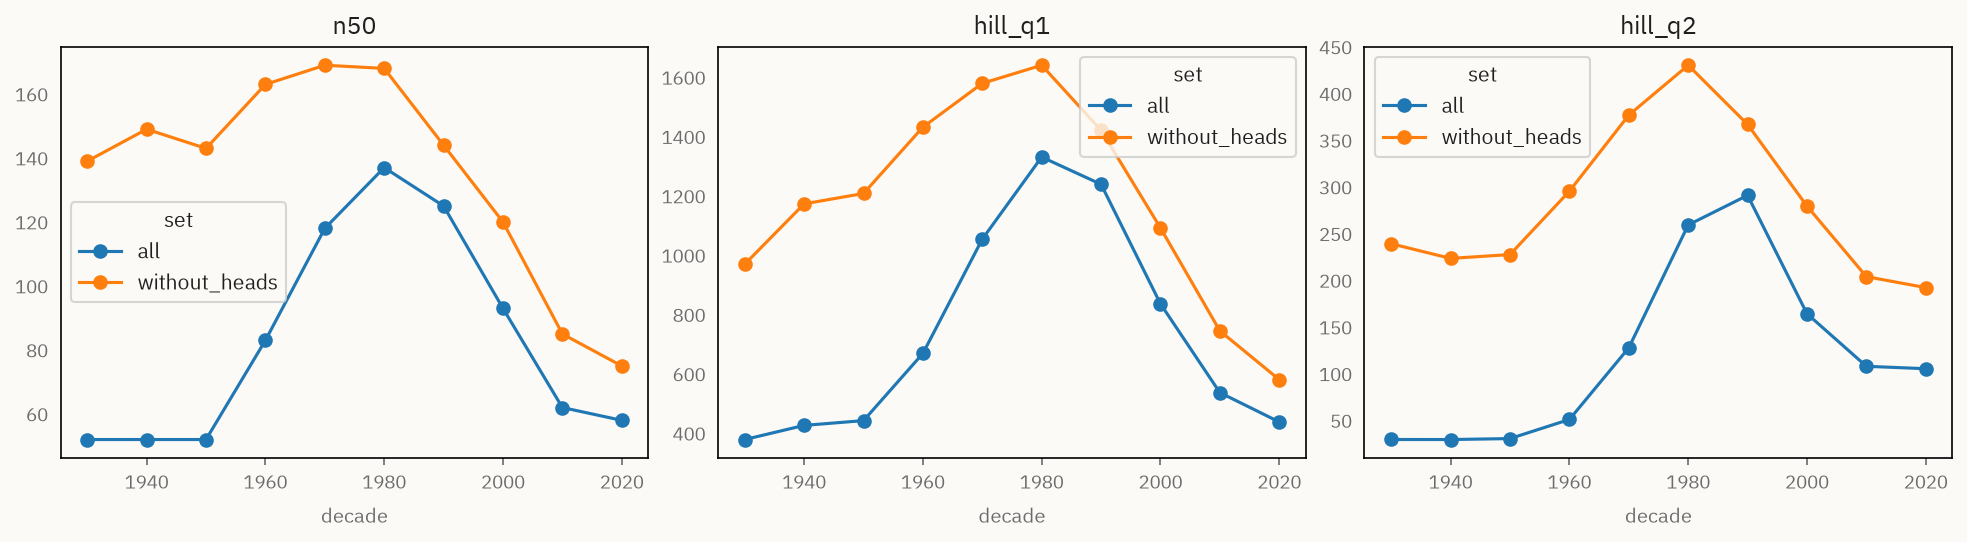

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for ax, measure in zip(axes, ["n50", "hill_q1", "hill_q2"], strict=True):
    diversity.pivot(index="decade", columns="set", values=measure).plot(
        ax=ax, marker="o", title=measure
    )
plt.show()

With every name counted, half of the listed people of 1930, 1940 and 1950 bear one of 52 names, and `maria` alone accounts for 16% to 17% of them. Concentration then falls: $n_{50}$ reaches 137 in 1980 and ${}^{2}D$ reaches 291 in 1990. It rises again from 2000, to $n_{50} = 58$ and ${}^{2}D = 105$ in 2020.

Without the four heads, the oldest decades are far less concentrated (${}^{2}D$ is 239 in 1930, against 30 with them), and $n_{50}$ stays between 139 and 169 from 1930 to 1980. The rise after 1990 remains: without the heads, $n_{50}$ is 85 in 2010 and 75 in 2020. Once the heads are removed, `antonio` leads every decade from 1930 to 1980, `lucas` leads 1990, `gabriel` 2000, and `davi` 2010 and 2020.

The disclosure threshold is a fixed count, so it cuts a larger share of a small decade: 20 people are $7.9 \times 10^{-6}$ of the listed people of 1930 and $6.8 \times 10^{-7}$ of those of 1980. `listed_names` and ${}^{1}D$ therefore lose more of their tail in 1930, 1940 and 2020 than in the large decades; $n_{50}$, the top shares and ${}^{2}D$ rest mainly on the common names. Section 4.1 applies one cut-off to every decade.

The renewed concentration holds in the 2010 label as well as in the 2020 label, whose span of birth years is unknown (section 3.2): $n_{50}$ is 137 in 1980, 62 in 2010 and 58 in 2020, and without the heads 168, 85 and 75.

### 4.1 Robustness: one cut-off for every decade

The threshold of 20 people is a different share of each decade, $20 / L_d$. The largest of these shares belongs to the 1930 label, the smallest:

$$s^{*} = \max_d \frac{20}{L_d}.$$

Applying $s^{*}$ to every decade keeps the names with $p_{d,i} \ge s^{*}$, so every decade loses its tail at the same share. `share_kept` is the share of the decade's listed people that the kept names hold. Their shares are renormalised to sum to 1,

$$q_{d,i} = \frac{c_{d,i}}{\sum_{j \text{ kept}} c_{d,j}},$$

and ${}^{1}D$ and ${}^{2}D$ are recomputed from $q_{d,i}$ as in section 4.

In [11]:
listed_people = names_decade.groupby("decade")["count"].sum()
cutoff = (DISCLOSURE_THRESHOLD / listed_people).max()

kept = names_decade[
    names_decade["count"] / names_decade["decade"].map(listed_people) >= cutoff
].copy()
kept["kept_people"] = kept.groupby("decade")["count"].transform("sum")
kept["renormalised"] = kept["count"] / kept["kept_people"]
kept["entropy_term"] = -kept["renormalised"] * np.log(kept["renormalised"])
kept["simpson_term"] = kept["renormalised"] ** 2

kept_groups = kept.groupby("decade")
diversity_common_cutoff = pd.DataFrame(
    {
        "cutoff": cutoff,
        "names_kept": kept_groups.size(),
        "share_kept": kept_groups["count"].sum() / listed_people,
        "hill_q1": np.exp(kept_groups["entropy_term"].sum()),
        "hill_q2": 1 / kept_groups["simpson_term"].sum(),
    }
).reset_index()
print(f"Common cut-off: {cutoff:.4g}, the share of 20 people in the {listed_people.idxmin()} label")
display(diversity_common_cutoff)

# Side by side with the fixed threshold of section 4
display(
    diversity_common_cutoff[["decade", "hill_q1", "hill_q2"]].merge(
        diversity.loc[diversity["set"] == "all", ["decade", "hill_q1", "hill_q2"]],
        on="decade",
        suffixes=("_common_cutoff", "_fixed_threshold"),
    )
)

Common cut-off: 7.875e-06, the share of 20 people in the 1930 label


,decade,cutoff,names_kept,share_kept,hill_q1,hill_q2
0,1930,0.000008,5965,1.000000,378.654919,29.580753
1,1940,0.000008,5843,0.971665,345.896454,27.893554
2,1950,0.000008,5416,0.958844,321.583265,28.097428
3,1960,0.000008,5752,0.949328,456.124261,45.987272
4,1970,0.000008,6147,0.941633,691.921436,113.319124
5,1980,0.000008,6293,0.936393,848.924791,227.382015
6,1990,0.000008,6080,0.940638,812.473900,257.524746
7,2000,0.000008,5198,0.951892,585.399139,148.847274
8,2010,0.000008,4284,0.965327,411.049091,100.607102
9,2020,0.000008,3854,0.979554,376.221579,101.118793


,decade,hill_q1_common_cutoff,hill_q2_common_cutoff,hill_q1_fixed_threshold,hill_q2_fixed_threshold
0,1930,378.654919,29.580753,378.654919,29.580753
1,1940,345.896454,27.893554,426.345598,29.543975
2,1950,321.583265,28.097428,442.453753,30.561053
3,1960,456.124261,45.987272,668.997562,51.027135
4,1970,691.921436,113.319124,1054.346115,127.799354
5,1980,848.924791,227.382015,1331.044558,259.308113
6,1990,812.473900,257.524746,1239.085471,291.037848
7,2000,585.399139,148.847274,836.160083,164.268514
8,2010,411.049091,100.607102,536.857169,107.962865
9,2020,376.221579,101.118793,437.849415,105.383030


The direction of change matches section 4 from 1950 to 2020 for ${}^{1}D$ and from 1930 to 2010 for ${}^{2}D$, but between 1930 and 1950 ${}^{1}D$ falls under one cut-off (379, 346, 322) where it rises under the fixed threshold (379, 426, 442).

### 4.2 Robustness: concentration within women's and men's names

The older labels list more women than men: the `f` class holds 61.6% of the listed people of 1930 and about 48% from 2000 on (section 3.3), so a change from one label to the next could reflect the mix of the sexes rather than the names given within each. The measures of section 4 are therefore recomputed within each sex class $s$ of section 3.3, `f` and `m` (`other` is left out). The denominator is $L_{d,s}$, the listed people of decade $d$ in class $s$:

$$L_{d,s} = \sum_{i \in s} c_{d,i}, \qquad p_{d,s,i} = \frac{c_{d,i}}{L_{d,s}},$$

and the names of each decade and class are taken in the ordering.

In [12]:
# The ordering of section 4 within each decade and sex class; the class other is left out
sex_keys = ["decade", "sex_class"]
ranked_by_sex = decade_rows[decade_rows["sex_class"].isin(["f", "m"])].sort_values(
    ["decade", "sex_class", "count", "name"], ascending=[True, True, False, True]
)
ranked_by_sex["listed_people"] = ranked_by_sex.groupby(sex_keys)["count"].transform("sum")
ranked_by_sex["share"] = ranked_by_sex["count"] / ranked_by_sex["listed_people"]
ranked_by_sex["position"] = ranked_by_sex.groupby(sex_keys).cumcount() + 1
ranked_by_sex["cumulative"] = ranked_by_sex.groupby(sex_keys)["count"].cumsum()
ranked_by_sex["simpson_term"] = ranked_by_sex["share"] ** 2

# The measures as in section 4, with L_{d,s} in place of L_d
grouped_by_sex = ranked_by_sex.groupby(sex_keys)
first_by_sex = ranked_by_sex[ranked_by_sex["position"] == 1].set_index(sex_keys)
diversity_by_sex = pd.DataFrame(
    {
        "listed_people": grouped_by_sex["count"].sum(),
        "listed_names": grouped_by_sex.size(),
        "top1_name": first_by_sex["name"],
        "top1_share": first_by_sex["share"],
        "top10_share": ranked_by_sex[ranked_by_sex["position"] <= 10]
        .groupby(sex_keys)["count"]
        .sum()
        / grouped_by_sex["count"].sum(),
        "n50": ranked_by_sex[2 * ranked_by_sex["cumulative"] >= ranked_by_sex["listed_people"]]
        .groupby(sex_keys)["position"]
        .min(),
        "hill_q2": 1 / grouped_by_sex["simpson_term"].sum(),
    }
).reset_index()
display(diversity_by_sex)
display(
    diversity_by_sex.pivot(
        index="decade", columns="sex_class", values=["n50", "top10_share", "hill_q2"]
    )
)

,decade,sex_class,listed_people,listed_names,top1_name,top1_share,top10_share,n50,hill_q2
0,1930,f,1564081,3118,maria,0.272019,0.389289,30,13.009736
1,1930,m,899621,2133,jose,0.147829,0.448926,16,26.996843
2,1940,f,3740375,5602,maria,0.299736,0.410332,27,10.815112
3,1940,m,2838594,4479,jose,0.149608,0.430492,18,27.794711
4,1950,f,7397294,8204,maria,0.305710,0.413032,25,10.410350
5,1950,m,6194968,6920,jose,0.145923,0.416007,20,29.759309
6,1960,f,10580824,11568,maria,0.232459,0.342186,40,17.554190
7,1960,m,9324021,9346,jose,0.121200,0.356470,31,41.513415
8,1970,f,12507188,14362,maria,0.128926,0.263651,61,48.475002
9,1970,m,11476977,11885,jose,0.077217,0.264923,45,80.271704


n50       top10_share               hill_q2            
sex_class     f     m           f         m           f           m
decade                                                             
1930       30.0  16.0    0.389289  0.448926   13.009736   26.996843
1940       27.0  18.0    0.410332  0.430492   10.815112   27.794711
1950       25.0  20.0    0.413032  0.416007   10.410350   29.759309
1960       40.0  31.0    0.342186  0.356470   17.554190   41.513415
1970       61.0  45.0    0.263651  0.264923   48.475002   80.271704
1980       80.0  51.0    0.192338  0.200255  119.062574  128.236348
1990       77.0  47.0    0.186601  0.197287  151.364060  130.766087
2000       63.0  34.0    0.248829  0.262512   73.977938   87.082170
2010       37.0  27.0    0.315364  0.310875   42.913914   67.685628
2020       29.0  28.0    0.334412  0.303884   39.188307   72.889641

Within each sex class, concentration falls from the 1950 label to the 1980 label and rises again after it, as with every name counted. Half of the people with `f` names share 25 names in 1950, 80 in 1980 and 29 in 2020; half of those with `m` names share 20, 51 and 28. Between 1930 and 1950 the classes move apart: concentration rises slightly in `f` ($n_{50}$ from 30 to 25) and falls slightly in `m` (16 to 20). ${}^{2}D$ follows the same path, from 10 (`f`) and 30 (`m`) in 1950 to 119 and 128 in 1980, and 39 and 73 in 2020. The fall and rise of concentration in section 4 therefore does not come from the changing share of women among the listed people.

$n_{50}$ is higher for `f` than for `m` in every label, while ${}^{2}D$, driven by the commonest names, is lower for `f` in every label but 1990, because `maria` alone holds a large share of the `f` names (section 6.1).

### 4.3 The ten most common names within each sex class

The figure takes the first ten names of each decade and sex class from the ranking in section 4.2, ordered by count descending and then name ascending. Each share uses all listed people of that decade and sex class as its denominator.

In [13]:
top_names_by_sex = (
    ranked_by_sex.loc[
        ranked_by_sex["position"] <= TOP_NAMES,
        ["decade", "sex_class", "position", "name", "count", "share"],
    ]
    .rename(columns={"position": "rank", "share": "share_within_sex"})
    .reset_index(drop=True)
)

## 5. Names that mark a generation

A name marks decade $d$ when its share there is high compared with the other nine decades pooled. With $c_{\neg d,i}$ and $L_{\neg d}$ summed over the other decades, Hardie's Log Ratio is

$$p_{\neg d,i} = \frac{c_{\neg d,i} + 0.5}{L_{\neg d} + 0.5}, \qquad \text{LR}_{d,i} = \log_2 \frac{p_{d,i}}{p_{\neg d,i}}.$$

Each unit of LR doubles the ratio: a name with LR = 3 is eight times as common, relative to the listed people, in decade $d$ as in the others. The 0.5 keeps the ratio finite for names listed in one decade only. Only names held by at least 1 in 2,000 listed people of the decade qualify, so the list is not led by rare names; the 20 with the highest LR are kept, ties going to the larger count.

In [14]:
decade_shares = names_decade.assign(
    listed_people=names_decade["decade"].map(listed_people),
    # The name's count over the other nine decades, 0 where it is listed in this decade only
    count_elsewhere=names_decade.groupby("name")["count"].transform("sum") - names_decade["count"],
)
decade_shares["listed_elsewhere"] = listed_people.sum() - decade_shares["listed_people"]
decade_shares["share_in_decade"] = decade_shares["count"] / decade_shares["listed_people"]
decade_shares["share_elsewhere"] = (decade_shares["count_elsewhere"] + SMOOTHING) / (
    decade_shares["listed_elsewhere"] + SMOOTHING
)
decade_shares["log_ratio"] = np.log2(
    decade_shares["share_in_decade"] / decade_shares["share_elsewhere"]
)

distinctive = (
    decade_shares[decade_shares["share_in_decade"] >= DISTINCTIVE_MIN_SHARE]
    .sort_values(["decade", "log_ratio", "count", "name"], ascending=[True, False, False, True])
    .groupby("decade")
    .head(DISTINCTIVE_TOP)
)
distinctive["rank"] = distinctive.groupby("decade").cumcount() + 1
distinctive = distinctive[
    ["decade", "name", "count", "share_in_decade", "share_elsewhere", "log_ratio", "rank"]
].reset_index(drop=True)

# The five most distinctive names of each decade, with their Log Ratio
top_five = distinctive[distinctive["rank"] <= 5]
display(
    (top_five["name"] + " " + top_five["log_ratio"].round(1).astype(str))
    .set_axis(pd.MultiIndex.from_frame(top_five[["rank", "decade"]]))
    .unstack("decade")
)

decade,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
rank,,,,,,,,,,
1,therezinha 5.8,mercedes 3.4,creusa 2.6,amarildo 3.1,valdirene 2.8,eder 2.7,jessica 3.9,kailane 4.2,sophia 3.8,gael 7.0
2,thereza 5.4,alzira 3.2,cleuza 2.6,tania 2.4,andrea 2.7,lidiane 2.6,gessica 3.8,camile 3.2,sofia 3.5,ravi 6.6
3,edith 4.5,leonor 3.1,neusa 2.5,salete 2.3,sandro 2.3,tatiane 2.5,romario 3.3,cauan 2.8,enzo 3.5,noa 6.6
4,julieta 4.1,irma 3.1,teresinha 2.5,margarete 2.3,adriana 2.3,tatiana 2.5,mayara 2.7,caua 2.8,valentina 3.3,noah 6.2
5,yolanda 4.1,elvira 3.1,neuza 2.5,fatima 2.2,vanusa 2.3,michelle 2.5,dayane 2.7,vitoria 2.7,emanuelly 3.3,zoe 6.1


The most distinctive names of 1930 (`therezinha`, `thereza`, `edith`, `julieta`, `yolanda`) have Log Ratios between 4.1 and 5.8, so each is between about 17 and 54 times as common, relative to the listed people, as in the other decades pooled. The lists of 1950 to 1980 are the flattest: their leaders score between 2.6 and 3.1 and their twentieth names between 1.9 and 2.3. The 2020 label has the most distinctive list, led by `gael` (7.0, about 128 times) with `ravi`, `noa`, `noah` and `zoe`, and all of its twenty names score at least 4.9.

Spelling variants appear as separate names because IBGE counts them separately: `jessica` and `gessica` are the two most distinctive names of 1990, `cauan` and `caua` both reach the top five of 2000, `sophia` and `sofia` that of 2010, and `noa` and `noah` that of 2020.

### 5.1 Names for the generation figure

`generation_names.csv` uses the same minimum share and Log Ratio ordering as `distinctive_names.csv`, with one additional condition: a name's share must peak in the decade it represents. Ties in peak share go to the earlier decade. The figure draws each name's trajectory, so a name chosen to mark a decade should peak in it. The count of bearers comes from the national table. The share born at the peak uses the sum of the name's listed decade counts, so its numerator and denominator cover the same set of decades.

In [15]:
# Sorting the decade columns lets idxmax choose the earliest decade when shares tie.
shares_by_name = (
    decade_shares.pivot(index="name", columns="decade", values="share_in_decade")
    .sort_index(axis="columns")
    .fillna(0)
)
decades = shares_by_name.columns.to_numpy()
generation_names = decade_shares.assign(
    peak_decade=decade_shares["name"].map(shares_by_name.idxmax(axis="columns")),
    sex_class=decade_shares["name"].map(name_classes["sex_class"]),
    bearers=decade_shares["name"].map(name_classes["count"]),
    share_born_at_peak=decade_shares["count"]
    / (decade_shares["count"] + decade_shares["count_elsewhere"]),
)
generation_names = (
    generation_names[
        (generation_names["decade"] == generation_names["peak_decade"])
        & (generation_names["share_in_decade"] >= DISTINCTIVE_MIN_SHARE)
    ]
    .sort_values(["decade", "log_ratio", "count", "name"], ascending=[True, False, False, True])
    .groupby("decade")
    .head(GENERATION_NAMES)
)
generation_names["rank"] = generation_names.groupby("decade").cumcount() + 1
generation_names = generation_names[
    [
        "decade",
        "rank",
        "name",
        "count",
        "share_in_decade",
        "log_ratio",
        "peak_decade",
        "sex_class",
        "bearers",
        "share_born_at_peak",
    ]
].reset_index(drop=True)

## 6. Maria, Ana, João and José

The four most common names in the national table, as shares of the listed people of each decade, $p_{d,i} = c_{d,i} / L_d$.

IBGE counts only the first word of the name field ([technical note 01/2025](https://censo2022.ibge.gov.br/nomes/nota_tecnica/notatecnica.pdf)), so a Maria Eduarda is counted as `maria`. A rise in the share of a head name therefore cannot be separated, in these data, from a rise in compound names that begin with it.

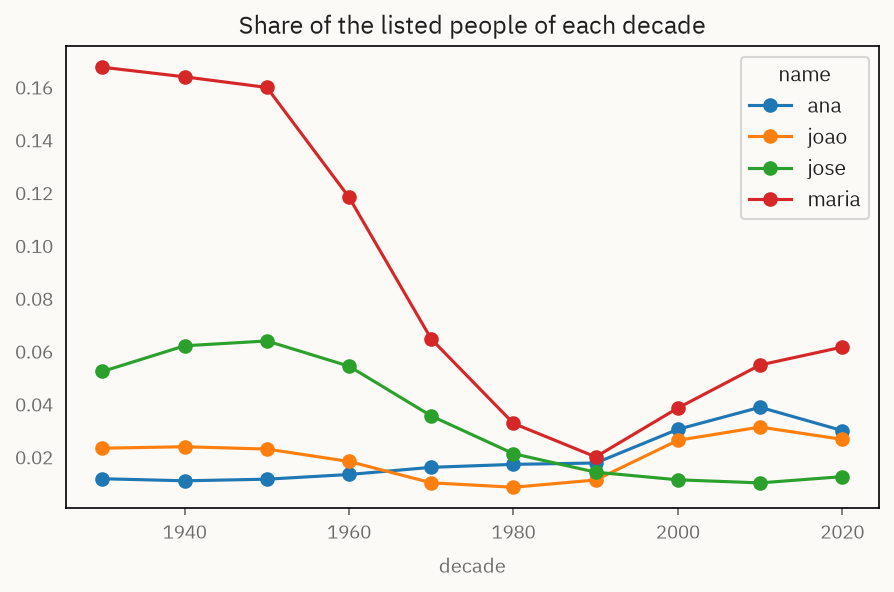

name,ana,joao,jose,maria
decade,,,,
1930,0.011751,0.023318,0.052362,0.167515
1940,0.010976,0.023861,0.062080,0.163888
1950,0.011579,0.022990,0.063906,0.159869
1960,0.013363,0.018295,0.054340,0.118272
1970,0.016071,0.010208,0.035517,0.064624
1980,0.017193,0.008530,0.021233,0.032696
1990,0.017715,0.011279,0.014230,0.020023
2000,0.030457,0.026297,0.011348,0.038521
2010,0.038807,0.031329,0.010177,0.054810


In [16]:
heads = names_decade[names_decade["name"].isin(HEADS)].copy()
heads["share"] = heads["count"] / heads["decade"].map(listed_people)
heads = heads[["decade", "name", "count", "share"]].sort_values(
    ["decade", "name"], ignore_index=True
)

heads.pivot(index="decade", columns="name", values="share").plot(
    marker="o", figsize=(7, 4), title="Share of the listed people of each decade"
)
plt.show()
display(heads.pivot(index="decade", columns="name", values="share"))

`maria` falls from 16.8% of the listed people of 1930 to 2.0% in 1990, then rises to 6.2% in 2020. `jose` peaks at 6.4% in 1950 and falls to about 1% from 2000 on, without a comparable rise. `joao` falls from 2.4% in 1940 to 0.9% in 1980 and returns to 3.1% in 2010. `ana` stays between 1.1% and 1.2% until 1950, rises to 1.8% in 1990 and 3.9% in 2010, and is at 3.0% in 2020.

These data cannot tell how much of the rise of `maria`, `ana` and `joao` after 1990 comes from compound names such as Maria Eduarda, Ana Clara or João Pedro, since only the first word is counted.

### 6.1 The four heads within their sex class

`maria` and `ana` are in class `f`, `joao` and `jose` in class `m` (section 3.3). Each head's share of the listed people of its own class, $c_{d,i} / L_{d,s}$ with $L_{d,s}$ from section 4.2, takes the changing mix of the sexes out of the shares above.

In [17]:
# Each head's count over the listed people of its own sex class in the decade
heads_by_sex = ranked_by_sex.loc[
    ranked_by_sex["name"].isin(HEADS), ["decade", "name", "sex_class", "count", "listed_people"]
]
heads_by_sex["share_within_sex"] = heads_by_sex["count"] / heads_by_sex["listed_people"]
heads_by_sex = heads_by_sex.drop(columns="listed_people").sort_values(
    ["decade", "name"], ignore_index=True
)
display(heads_by_sex.pivot(index="decade", columns="name", values="share_within_sex"))

name,ana,joao,jose,maria
decade,,,,
1930,0.019081,0.065831,0.147829,0.272019
1940,0.020074,0.057503,0.149608,0.299736
1950,0.022143,0.052496,0.145923,0.305710
1960,0.026265,0.040805,0.121200,0.232459
1970,0.032061,0.022194,0.077217,0.128926
1980,0.034168,0.018120,0.045102,0.064978
1990,0.035592,0.023257,0.029342,0.040228
2000,0.062932,0.052142,0.022501,0.079595
2010,0.080379,0.061528,0.019988,0.113526


Within their class, `maria` holds 27.2% of the people with `f` names in 1930 and 30.6% in 1950, falls to 4.0% in 1990 and returns to 12.7% in 2020. `ana` rises in every label from 1.9% in 1930 to 8.0% in 2010, then falls to 6.2% in 2020. `joao` falls from 6.6% of the people with `m` names in 1930 to 1.8% in 1980, and returns to 6.2% in 2010 and 5.3% in 2020. `jose` holds about 15% of them from 1930 to 1950 and between 2.0% and 2.5% from 2000 on.

## 7. Spelling

Five spelling patterns are matched with `re.search` on IBGE's form of each name (lower case, no diacritics); `any` matches a name with at least one of them.

| Pattern | Regular expression | Examples |
| --- | --- | --- |
| `kwy` | `[kwy]` | Kauã, Wesley, Yasmin |
| `th` | `th` | Thiago, Matheus, Arthur |
| `double_consonant` | `(bb\|dd\|ff\|gg\|ll\|mm\|nn\|pp\|tt\|zz)` | Allana, Emmanuel, Giovanna |
| `son_ending` | `son$` | Anderson, Emerson |
| `ton_ending` | `ton$` | Wellington, Milton |

For each decade and sex class (`all`, `f`, `m`), the share is the number of listed people whose name matches over all listed people of that decade and class:

$$s_{d,k} = \frac{\sum_{i \in k,\ i \text{ matches}} c_{d,i}}{\sum_{i \in k} c_{d,i}}.$$

In [18]:
# One flag per pattern and name, from Python's re.search on the IBGE form
pattern_flags = names_total[["name"]].copy()
for pattern, regex in SPELLING_PATTERNS.items():
    pattern_flags[pattern] = [re.search(regex, name) is not None for name in pattern_flags["name"]]
pattern_flags["any"] = pattern_flags[list(SPELLING_PATTERNS)].any(axis=1)

# One row per decade, name and pattern; the class "all" repeats every row, "f" and "m" their own
matches = decade_rows[["decade", "name", "count", "sex_class"]].merge(
    pattern_flags.melt(id_vars="name", var_name="pattern", value_name="matches"), on="name"
)
by_class = pd.concat(
    [matches.assign(sex_class="all"), matches[matches["sex_class"].isin(["f", "m"])]],
    ignore_index=True,
)
spelling = (
    by_class.assign(people=by_class["count"].where(by_class["matches"], 0))
    .groupby(["decade", "pattern", "sex_class"])
    .agg(people=("people", "sum"), names=("matches", "sum"), listed=("count", "sum"))
    .reset_index()
)
spelling["share"] = spelling["people"] / spelling["listed"]
spelling = spelling[["decade", "pattern", "sex_class", "people", "share", "names"]]

display(
    spelling[spelling["sex_class"] == "all"].pivot(
        index="decade", columns="pattern", values="share"
    )
)

# The peak of each pattern within each sex class, which the text below quotes
display(
    spelling.loc[
        spelling.groupby(["pattern", "sex_class"])["share"].idxmax(),
        ["pattern", "sex_class", "decade", "share"],
    ].set_index(["pattern", "sex_class"])
)

pattern,any,double_consonant,kwy,son_ending,th,ton_ending
decade,,,,,,
1930,0.046046,0.004751,0.025857,0.006504,0.008458,0.002914
1940,0.036041,0.001352,0.017469,0.010977,0.003871,0.004836
1950,0.040446,0.001212,0.016502,0.015439,0.004102,0.006711
1960,0.055027,0.002165,0.019917,0.024844,0.003451,0.009480
1970,0.079302,0.006714,0.029875,0.037320,0.003314,0.011709
1980,0.121729,0.018984,0.051152,0.043037,0.013095,0.014809
1990,0.173659,0.030626,0.086955,0.043128,0.030387,0.013350
2000,0.200429,0.042625,0.122262,0.028821,0.033869,0.007774
2010,0.192198,0.051753,0.119322,0.013926,0.040479,0.003166


decade     share
pattern          sex_class                  
any              all          2000  0.200429
                 f            2010  0.199986
                 m            1990  0.211350
double_consonant all          2010  0.051753
                 f            2010  0.090021
                 m            1990  0.023963
kwy              all          2000  0.122262
                 f            2000  0.141015
                 m            2000  0.101683
son_ending       all          1990  0.043128
                 f            1930  0.000000
                 m            1980  0.091415
th               all          2020  0.051694
                 f            1990  0.027692
                 m            2020  0.081756
ton_ending       all          1980  0.014809
                 f            1930  0.000000
                 m            1980  0.031458

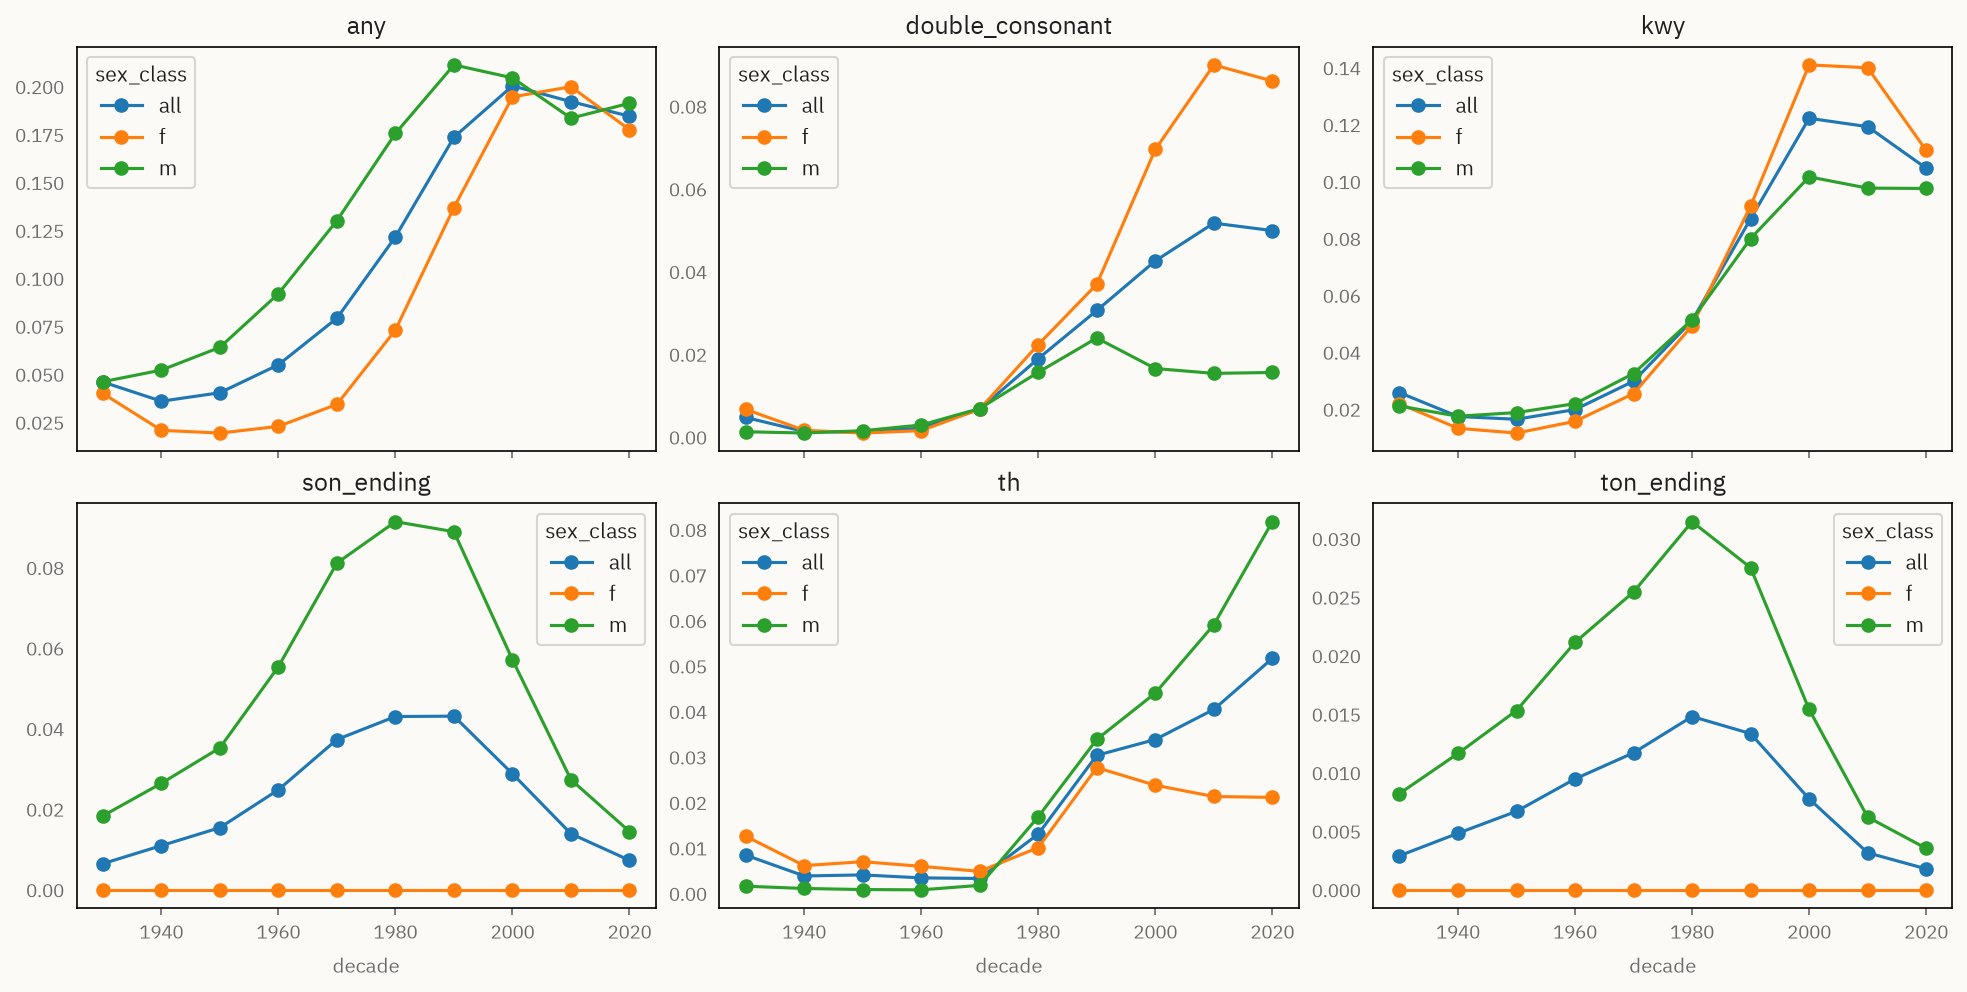

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, layout="constrained")
for ax, (pattern, rows) in zip(axes.flat, spelling.groupby("pattern"), strict=True):
    rows.pivot(index="decade", columns="sex_class", values="share").plot(
        ax=ax, marker="o", title=pattern
    )
plt.show()

The share of listed people whose name matches at least one pattern rises from 3.6% in 1940 to 20.0% in 2000 and is 19.2% in 2010 and 18.5% in 2020. `kwy` follows the same path, from 1.7% in 1940 to 12.2% in 2000. The `son` and `ton` endings rise and then fall: `son_ending` peaks at 4.3% in 1980 and 1990 and is 0.7% in 2020, and `ton_ending` peaks at 1.5% in 1980. `th` and `double_consonant` are both higher in 1930 than in the 1940s to 1960s, then rise to between 4% and 5.2% in 2010 and 2020.

By sex class, the rise is earlier among `m` names: `any` covers 13.0% of the listed people with `m` names in 1970, against 3.4% with `f` names, and the two classes are close from 2000 on (20.5% and 19.5%). `kwy` is more common among `f` names from 1990. The `son` and `ton` endings belong to `m` names: among them, `son_ending` reaches 9.1% in 1980 and `ton_ending` 3.1%, while both stay below 0.01% among `f` names. `double_consonant` reaches 9.0% of the `f` listed people in 2010, and `th` 8.2% of the `m` listed people in 2020.

In the oldest labels, `th` comes mostly from women's names (class `f`) such as `therezinha` and `thereza`; since the 1980s it comes mostly from men's names (class `m`).

After 1990 the `son` and `ton` endings part from `kwy`: `kwy` stays near its peak (12.2% of all listed people in 2000, 10.5% in 2020), while `son_ending` falls from 4.3% in 1990 to 0.7% in 2020 and `ton_ending` from 1.3% to 0.2%.

## 8. Life cycles of names

### 8.1 Eligibility

A name enters the analysis if it accounts for at least 1 in 2,000 listed people in any decade label. Shares use all listed people of the decade, across sex classes.

In [20]:
eligible_shares = shares_by_name[shares_by_name.max(axis="columns") >= LIFE_CYCLE_MIN_SHARE]

### 8.2 Features

Use the base-10 logarithm of a name's share in each decade. For an absent decade, use $10^{-6}$ as a small positive proxy. This proxy is below the disclosure share in the oldest and youngest labels, but the threshold of 20 bearers divided by the listed population falls below it from 1960 to 2010. Observed shares are kept even when they fall below the proxy. Centre and scale each name's ten log shares using its own mean and sample standard deviation, so the fit compares shapes.

In [21]:
log_shares = np.log10(eligible_shares.mask(eligible_shares.eq(0), LIFE_CYCLE_ABSENT_SHARE))
life_cycle_features = log_shares.sub(log_shares.mean(axis="columns"), axis="index").div(
    log_shares.std(axis="columns"), axis="index"
)

### 8.3 Model and display scale

Fit scikit-learn k-means with six clusters, 100 initialisations and random state 0. For display, divide each name's share by its own maximum, then take the base-10 log and clip at $-3$. A value of 0 is the peak and $-3$ represents one thousandth of the peak or less, including unlisted decades.

In [22]:
relative_shares = np.log10(
    eligible_shares.div(eligible_shares.max(axis="columns"), axis="index").clip(lower=1e-3)
)

### 8.4 Identifying and ordering the groups

Compute each group's median on the display scale. The comeback score adds the group's median in 1930 and its median in 2020, each measured above the lowest median between 1960 and 1990 inclusive. Put the group with the greatest score last. Order the others by the decade of their median's maximum, taking the first decade if the maximum ties. Ties between groups in that ordering follow the model's label order.

In [23]:
def fit_life_cycles(k, n_init, seed):
    """Fit k-means and identify the comeback group by the median's rebound score."""
    with threadpool_limits(limits=1):
        labels = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit_predict(
            life_cycle_features
        )
    medians = relative_shares.groupby(labels).median()
    trough = medians.loc[:, 1960:1990].min(axis="columns")
    comeback_scores = medians[FIRST_DECADE] + medians[LAST_DECADE] - 2 * trough
    return labels, medians, comeback_scores.idxmax()


life_cycle_labels, life_cycle_medians, comeback_label = fit_life_cycles(LIFE_CYCLE_K, 100, 0)
median_peaks = life_cycle_medians.idxmax(axis="columns").drop(index=comeback_label)
display_order = [*median_peaks.sort_values(kind="stable").index, comeback_label]
group_by_label = {label: position for position, label in enumerate(display_order, start=1)}
life_cycles = (
    relative_shares.add_prefix("relative_")
    .assign(group=[group_by_label[label] for label in life_cycle_labels])
    .reset_index()[["name", "group", *(f"relative_{decade}" for decade in decades)]]
)

### 8.5 Robustness

For $k=3$ to $10$, report the silhouette on the standardised features. For $k=5$ to $8$, also compare comeback membership with that of the six-cluster fit. Repeat the six-cluster fit for seeds 0 through 9 using 20 initialisations and compare each comeback group with the seed-0 group from that series. Report the intersection size and Jaccard overlap (intersection divided by union), and record the earliest decade of the median's minimum.

In [24]:
def comeback_overlap(labels, medians, comeback, reference_members):
    """Measure membership overlap and locate the trough of the comeback median."""
    members = relative_shares.index[labels == comeback]
    shared = len(members.intersection(reference_members))
    return {
        "comeback_size": len(members),
        "overlap_count": shared,
        "overlap_jaccard": shared / len(members.union(reference_members)),
        "comeback_trough_decade": medians.loc[comeback].idxmin(),
    }


main_members = relative_shares.index[life_cycle_labels == comeback_label]
robustness = []
for k in range(3, 11):
    if k == LIFE_CYCLE_K:
        labels, medians, comeback = life_cycle_labels, life_cycle_medians, comeback_label
    else:
        labels, medians, comeback = fit_life_cycles(k, 100, 0)
    with threadpool_limits(limits=1):
        silhouette = silhouette_score(life_cycle_features, labels)
    row = {"comparison": "resolution", "k": k, "seed": 0, "n_init": 100, "silhouette": silhouette}
    if 5 <= k <= 8:
        row.update(comeback_overlap(labels, medians, comeback, main_members))
    robustness.append(row)

seed_zero_fit = fit_life_cycles(LIFE_CYCLE_K, 20, 0)
seed_zero_members = relative_shares.index[seed_zero_fit[0] == seed_zero_fit[2]]
for seed in range(10):
    labels, medians, comeback = (
        seed_zero_fit if seed == 0 else fit_life_cycles(LIFE_CYCLE_K, 20, seed)
    )
    robustness.append(
        {
            "comparison": "seed",
            "k": LIFE_CYCLE_K,
            "seed": seed,
            "n_init": 20,
            **comeback_overlap(labels, medians, comeback, seed_zero_members),
        }
    )

life_cycle_robustness = pd.DataFrame(robustness).astype(
    {"comeback_size": "Int64", "overlap_count": "Int64", "comeback_trough_decade": "Int64"}
)
display(life_cycle_robustness)

,comparison,k,seed,n_init,silhouette,comeback_size,overlap_count,overlap_jaccard,comeback_trough_decade
0,resolution,3,0,100,0.495982,<NA>,<NA>,NaN,<NA>
1,resolution,4,0,100,0.446497,<NA>,<NA>,NaN,<NA>
2,resolution,5,0,100,0.435969,75,56,0.736842,1970
3,resolution,6,0,100,0.411586,57,57,1.000000,1970
4,resolution,7,0,100,0.389753,34,27,0.421875,1990
5,resolution,8,0,100,0.383326,65,37,0.435294,1970
6,resolution,9,0,100,0.323973,<NA>,<NA>,NaN,<NA>
7,resolution,10,0,100,0.309848,<NA>,<NA>,NaN,<NA>
8,seed,6,0,20,NaN,57,57,1.000000,1970
9,seed,6,1,20,NaN,57,57,1.000000,1970


The silhouette does not single out six groups. Trajectories form a continuum by peak decade, and six groups give one resolution for displaying it. A comeback group separates at every resolution from five to eight. In the ten seed runs, nine return the same set of names as seed 0, while the other run keeps all of that set and adds eight names.

## 9. Results

The results tables, written as CSV with a header row and floats at full precision (pandas writes the shortest representation that reads back as the same number). The figures and the independent audit read them from `results/`.

In [25]:
RESULTS_DIR.mkdir(exist_ok=True)
results = {
    "diversity_by_decade.csv": diversity,
    "diversity_common_cutoff.csv": diversity_common_cutoff,
    "diversity_by_sex.csv": diversity_by_sex,
    "coverage_by_decade.csv": coverage,
    "distinctive_names.csv": distinctive,
    "heads_by_decade.csv": heads,
    "heads_by_sex.csv": heads_by_sex,
    "spelling_by_decade.csv": spelling,
    "sex_class_coverage.csv": sex_class_coverage,
    "top_names_by_sex.csv": top_names_by_sex,
    "generation_names.csv": generation_names,
    "life_cycles.csv": life_cycles,
    "life_cycle_robustness.csv": life_cycle_robustness,
}
for file_name, table in results.items():
    table.to_csv(RESULTS_DIR / file_name, index=False, encoding="utf-8")
    print(f"{file_name}: {len(table)} rows, columns {', '.join(table.columns)}")

diversity_by_decade.csv: 20 rows, columns decade, set, listed_people, listed_names, top1_name, top1_share, top10_share, top100_share, n50, hill_q1, hill_q2
diversity_common_cutoff.csv: 10 rows, columns decade, cutoff, names_kept, share_kept, hill_q1, hill_q2
diversity_by_sex.csv: 20 rows, columns decade, sex_class, listed_people, listed_names, top1_name, top1_share, top10_share, n50, hill_q2
coverage_by_decade.csv: 10 rows, columns decade, listed_people, census_people_plain, coverage_plain
distinctive_names.csv: 200 rows, columns decade, name, count, share_in_decade, share_elsewhere, log_ratio, rank
heads_by_decade.csv: 40 rows, columns decade, name, count, share
heads_by_sex.csv: 40 rows, columns decade, name, sex_class, count, share_within_sex
spelling_by_decade.csv: 180 rows, columns decade, pattern, sex_class, people, share, names
sex_class_coverage.csv: 30 rows, columns decade, sex_class, people, share
top_names_by_sex.csv: 200 rows, columns decade, sex_class, rank, name, count, s

## 10. Figures

The four figures of the post, each drawn in Brazilian Portuguese and in English from the results tables in `results/` and the committed processed tables. They are saved to `figures/` as 1080 × 1350 PNGs. All displayed names use `DISPLAY_NAMES`; the tables retain the IBGE spellings.

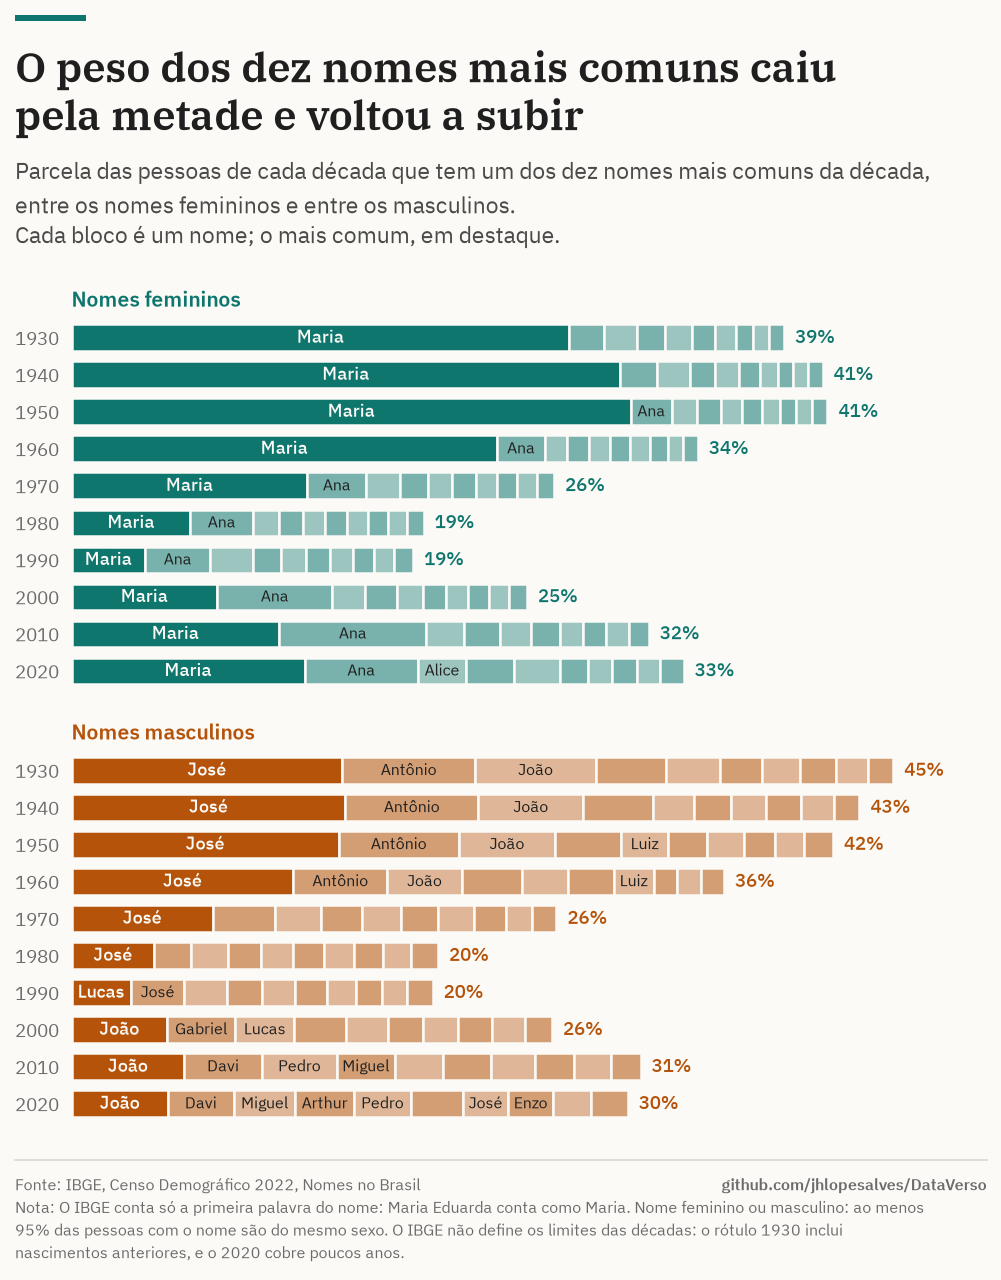

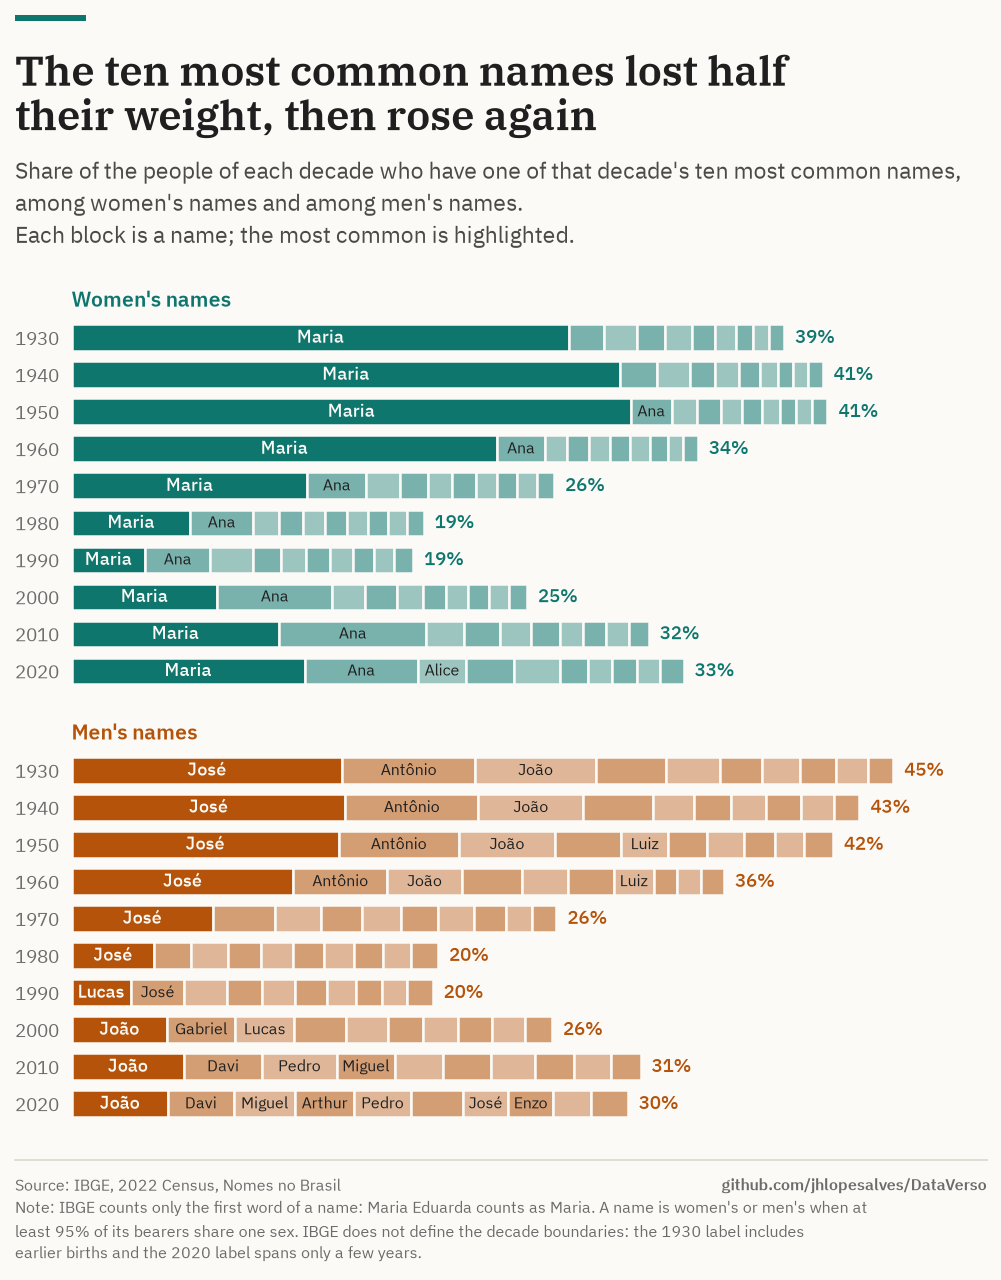

In [26]:
# Figure 1: the ten most common names of each decade and sex class
top_names_for_figure = pd.read_csv(RESULTS_DIR / "top_names_by_sex.csv")
top_ten_shares = top_names_for_figure.groupby(["decade", "sex_class"])["share_within_sex"].sum()
for sex, totals in top_ten_shares.unstack().items():
    minimum = totals.idxmin()
    early_level = totals.loc[1940:1950].min()
    if minimum <= 1950 or totals[minimum] > early_level / 2 or totals.iloc[-1] <= totals[minimum]:
        raise ValueError(f"The top-ten shares for {sex} do not support the figure title.")

# Both words occur in the national table. Their use as a compound is illustrative.
maria, eduarda = (DISPLAY_NAMES[name] for name in name_classes.loc[["maria", "eduarda"]].index)
sex_cutoff = f"{SEX_CLASS_THRESHOLD:.0%}"
TOP_NAMES_TEXT = {
    "pt": {
        "title": "O peso dos dez nomes mais comuns caiu\npela metade e voltou a subir",
        "subtitle": (
            "Parcela das pessoas de cada década que tem um dos dez nomes mais comuns da década,\n"
            "entre os nomes femininos e entre os masculinos.\n"
            "Cada bloco é um nome; o mais comum, em destaque."
        ),
        "panels": {"f": "Nomes femininos", "m": "Nomes masculinos"},
        "note": (
            f"O IBGE conta só a primeira palavra do nome: {maria} {eduarda} conta como {maria}. Nome feminino ou masculino: ao menos\n"
            f"{sex_cutoff} das pessoas com o nome são do mesmo sexo. O IBGE não define os limites das décadas: o rótulo {decades[0]} inclui\n"
            f"nascimentos anteriores, e o {decades[-1]} cobre poucos anos."
        ),
    },
    "en": {
        "title": "The ten most common names lost half\ntheir weight, then rose again",
        "subtitle": (
            "Share of the people of each decade who have one of that decade's ten most common names,\n"
            "among women's names and among men's names.\n"
            "Each block is a name; the most common is highlighted."
        ),
        "panels": {"f": "Women's names", "m": "Men's names"},
        "note": (
            f"IBGE counts only the first word of a name: {maria} {eduarda} counts as {maria}. A name is women's or men's when at\n"
            f"least {sex_cutoff} of its bearers share one sex. IBGE does not define the decade boundaries: the {decades[0]} label includes\n"
            f"earlier births and the {decades[-1]} label spans only a few years."
        ),
    },
}

for lang in LANGUAGES:
    text = TOP_NAMES_TEXT[lang]
    fig, axes = plt.subplots(2, 1, figsize=SOCIAL_SIZE, dpi=SOCIAL_DPI, sharex=True)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    for ax, sex in zip(axes, SEX_COLOURS, strict=True):
        ax.set_xlim(0, 0.50)
        ax.set_ylim(len(decades) - 0.5, -0.5)
        ax.set_yticks(range(len(decades)), decades.astype(str))
        ax.tick_params(axis="y", length=0, labelsize=9)
        ax.tick_params(axis="x", length=0, labelbottom=False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.set_title(
            text["panels"][sex],
            loc="left",
            fontsize=10,
            fontweight="semibold",
            color=SEX_COLOURS[sex],
            pad=6,
        )

    # Settle the axis range, ticks and titles before measuring any block or label.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax, (sex, colour) in zip(axes, SEX_COLOURS.items(), strict=True):
        group = top_names_for_figure[top_names_for_figure["sex_class"] == sex]
        for row, decade in enumerate(decades):
            left = 0.0
            for item in group[group["decade"] == decade].itertuples(index=False):
                leading = item.rank == 1
                share = item.share_within_sex
                face = colour if leading else tint(colour, 0.55 if item.rank % 2 == 0 else 0.40)
                ax.barh(
                    row, share, left=left, height=0.72, color=face, edgecolor=PAPER, linewidth=1.2
                )
                x0, x1 = ax.transData.transform([(left, 0), (left + share, 0)])[:, 0]
                # The prototype measures secondary clearance in renderer pixels, in total.
                clearance = renderer.points_to_pixels(4) if leading else 10
                free_width = x1 - x0 - clearance
                sizes = (8.6, 7.6, 6.8) if leading else (7.8,)
                label = ax.text(
                    left + share / 2,
                    row,
                    DISPLAY_NAMES[item.name],
                    ha="center",
                    va="center",
                    fontweight="medium" if leading else "regular",
                    color=PAPER if leading else INK,
                )
                for size in sizes:
                    label.set_fontsize(size)
                    if label.get_window_extent(renderer).width <= free_width:
                        break
                else:
                    label.remove()
                    if leading:
                        raise ValueError(
                            f"The label of {item.name} does not fit in {decade} ({sex})."
                        )
                left += share
            ax.text(
                left + 0.006,
                row,
                f"{top_ten_shares.loc[decade, sex]:.0%}",
                va="center",
                fontsize=9,
                color=colour,
                fontweight="medium",
            )
    fig.savefig(FIGURES_DIR / f"01_top_names_{lang}.png")
    plt.show()

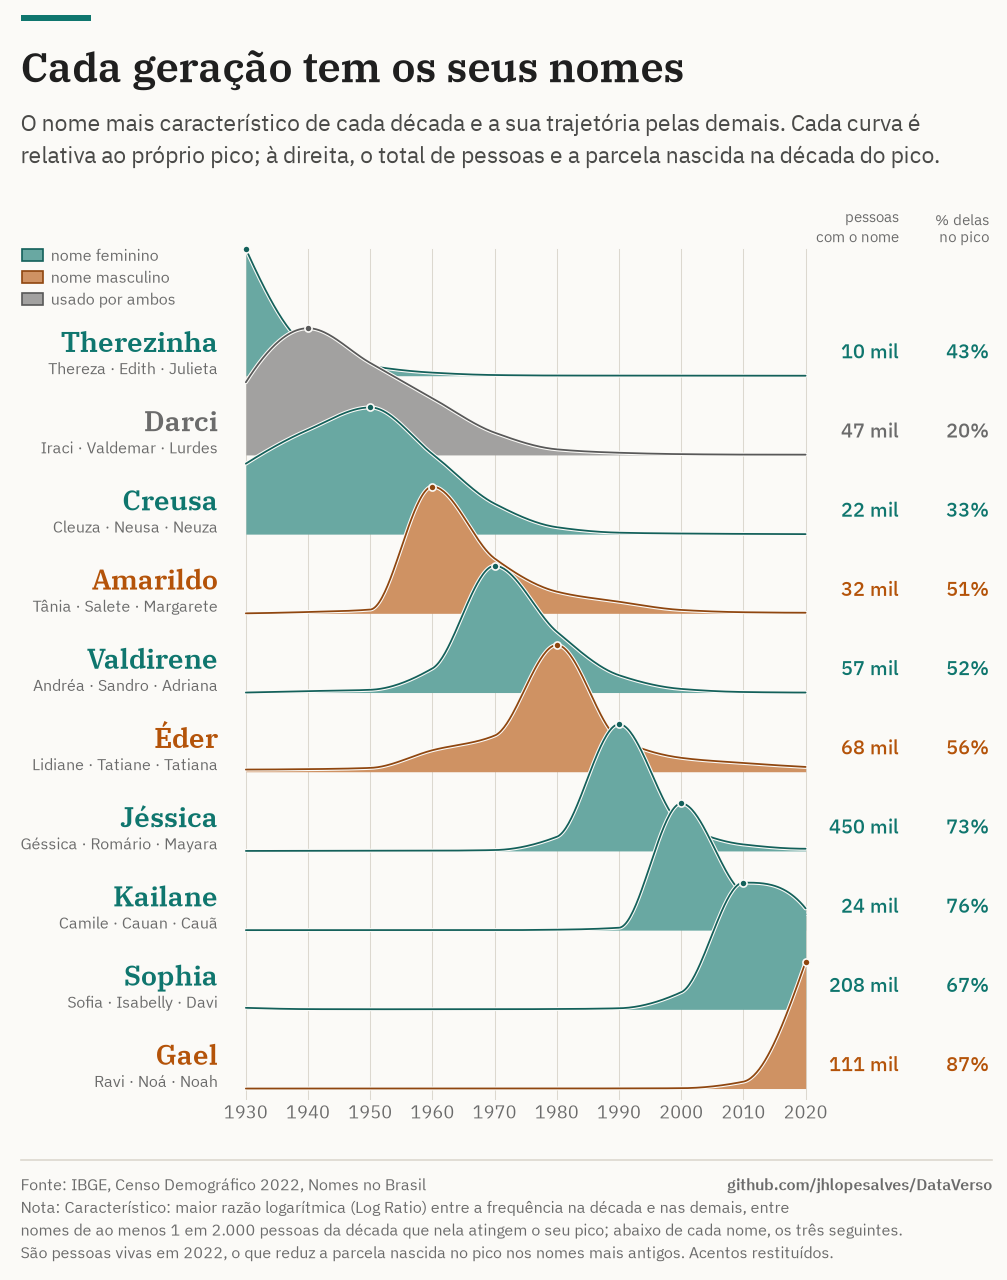

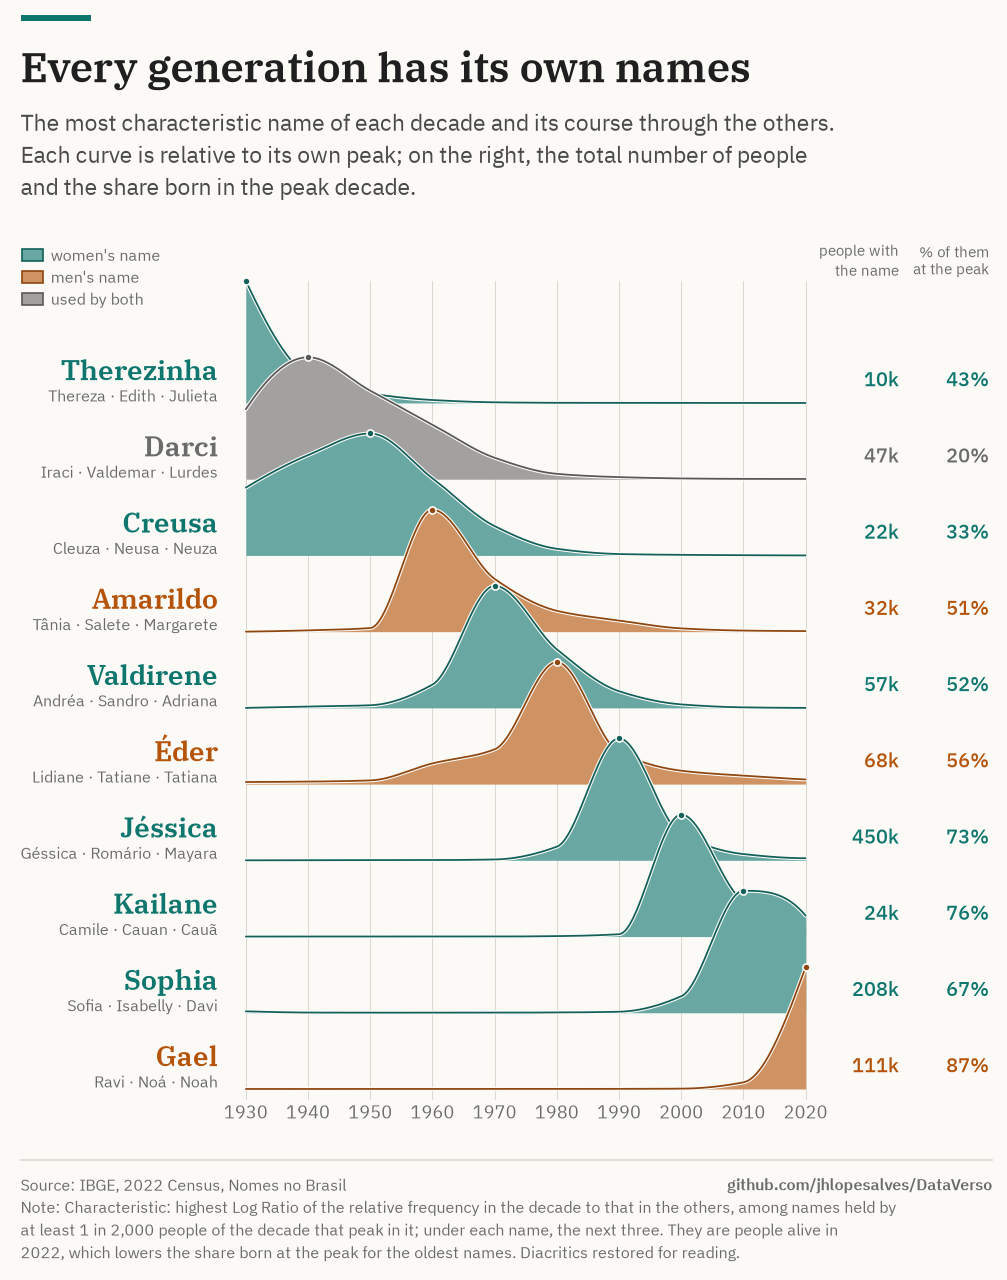

In [27]:
# Figure 2: the leading characteristic name of each decade and its three runners-up
generation_for_figure = pd.read_csv(RESULTS_DIR / "generation_names.csv")
expected_leaders = (
    "therezinha",
    "darci",
    "creusa",
    "amarildo",
    "valdirene",
    "eder",
    "jessica",
    "kailane",
    "sophia",
    "gael",
)
if tuple(generation_for_figure.loc[generation_for_figure["rank"] == 1, "name"]) != expected_leaders:
    raise ValueError("The generation names differ from the expected rank-1 names.")

minimum_bearers = round(1 / DISTINCTIVE_MIN_SHARE)
minimum_bearers_pt = f"{minimum_bearers:,}".replace(",", ".")
GENERATION_TEXT = {
    "pt": {
        "title": "Cada geração tem os seus nomes",
        "subtitle": (
            "O nome mais característico de cada década e a sua trajetória pelas demais. Cada curva é\n"
            "relativa ao próprio pico; à direita, o total de pessoas e a parcela nascida na década do pico."
        ),
        "note": (
            "Característico: maior razão logarítmica (Log Ratio) entre a frequência na década e nas demais, entre\n"
            f"nomes de ao menos 1 em {minimum_bearers_pt} pessoas da década que nela atingem o seu pico; abaixo de cada nome, os três seguintes.\n"
            f"São pessoas vivas em {REFERENCE_YEAR}, o que reduz a parcela nascida no pico nos nomes mais antigos. Acentos restituídos."
        ),
        "columns": ("pessoas\ncom o nome", "% delas\nno pico"),
        "key": ("nome feminino", "nome masculino", "usado por ambos"),
    },
    "en": {
        "title": "Every generation has its own names",
        "subtitle": (
            "The most characteristic name of each decade and its course through the others.\n"
            "Each curve is relative to its own peak; on the right, the total number of people\n"
            "and the share born in the peak decade."
        ),
        "note": (
            "Characteristic: highest Log Ratio of the relative frequency in the decade to that in the others, among names held by\n"
            f"at least 1 in {minimum_bearers:,} people of the decade that peak in it; under each name, the next three. They are people alive in\n"
            f"{REFERENCE_YEAR}, which lowers the share born at the peak for the oldest names. Diacritics restored for reading."
        ),
        "columns": ("people with\nthe name", "% of them\nat the peak"),
        "key": ("women's name", "men's name", "used by both"),
    },
}

x = np.arange(len(decades))
fine = np.linspace(x[0], x[-1], 400)
wave_height = 1.6  # Ridges rise into the row above.
wave_colours = {**SEX_COLOURS, "other": MUTED}
for lang in LANGUAGES:
    text = GENERATION_TEXT[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE, dpi=SOCIAL_DPI)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    for d_index in x:
        ax.plot(
            [d_index, d_index], [-0.15, x[-1] + wave_height], color=RULE, linewidth=0.5, zorder=0
        )
    for row, (_, names) in enumerate(generation_for_figure.groupby("decade", sort=True)):
        leader = names.iloc[0]
        values = shares_by_name.loc[leader["name"]].to_numpy()
        base = x[-1] - row
        curve = PchipInterpolator(x, values / values.max())(fine)
        colour = wave_colours[leader["sex_class"]]
        edge = shade(colour, 0.25)
        z = 10 + row * 3  # Later decades sit in front.
        ax.fill_between(
            fine, base, base + curve * wave_height, color=tint(colour, 0.62), linewidth=0, zorder=z
        )
        ax.plot(
            fine,
            base + curve * wave_height,
            color=edge,
            linewidth=0.85,
            zorder=z + 1,
            solid_capstyle="round",
            solid_joinstyle="round",
            path_effects=[
                patheffects.Stroke(linewidth=1.9, foreground=PAPER),
                patheffects.Normal(),
            ],
        )
        peak = int(np.searchsorted(decades, leader["peak_decade"]))
        ax.plot(
            x[peak],
            base + wave_height,
            "o",
            color=edge,
            markersize=3.4,
            zorder=z + 2,
            markeredgecolor=PAPER,
            markeredgewidth=0.8,
        )
        thousands = f"{leader['bearers'] / 1000:,.0f}"
        count_label = f"{thousands.replace(',', '.')} mil" if lang == "pt" else f"{thousands}k"
        for col_x, value in ((10.5, count_label), (11.95, f"{leader['share_born_at_peak']:.0%}")):
            ax.text(
                col_x,
                base + 0.22,
                value,
                ha="right",
                va="baseline",
                fontsize=9.5,
                color=colour,
                fontweight="medium",
                clip_on=False,
            )
        ax.text(
            -0.45,
            base + 0.30,
            DISPLAY_NAMES[leader["name"]],
            ha="right",
            va="baseline",
            fontsize=13.5,
            fontfamily=TITLE_FONT,
            fontweight="semibold",
            color=colour,
        )
        ax.text(
            -0.45,
            base + 0.02,
            " · ".join(DISPLAY_NAMES[name] for name in names["name"].iloc[1:]),
            ha="right",
            va="baseline",
            fontsize=7.6,
            color=MUTED,
        )
    for col_x, header in zip((10.5, 11.95), text["columns"], strict=True):
        ax.text(
            col_x,
            x[-1] + wave_height + 0.02,
            header,
            ha="right",
            va="bottom",
            fontsize=7.4,
            color=MUTED,
            linespacing=1.2,
            clip_on=False,
        )
    key = fig.legend(
        handles=[
            Patch(facecolor=tint(colour, 0.62), edgecolor=shade(colour, 0.25), linewidth=0.8)
            for colour in wave_colours.values()
        ],
        labels=text["key"],
        loc="upper left",
        bbox_to_anchor=(0.045, 0.792),
        ncol=1,
        frameon=False,
        fontsize=7.8,
        handlelength=1.3,
        handleheight=0.8,
        labelspacing=0.35,
        handletextpad=0.5,
        borderaxespad=0.0,
    )
    for label in key.get_texts():
        label.set_color(MUTED)
    ax.set_xticks(x, decades.astype(str))
    ax.set_xlim(-0.15, 12.0)
    ax.set_ylim(-0.15, x[-1] + wave_height + 0.12)
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="x", length=0, labelsize=8.5, pad=2)
    fig.savefig(FIGURES_DIR / f"02_generations_{lang}.png")
    plt.show()

alice: yes (comeback group)
helena: yes (comeback group)
cecilia: yes (comeback group)
joaquim: yes (comeback group)
aurora: yes (comeback group)


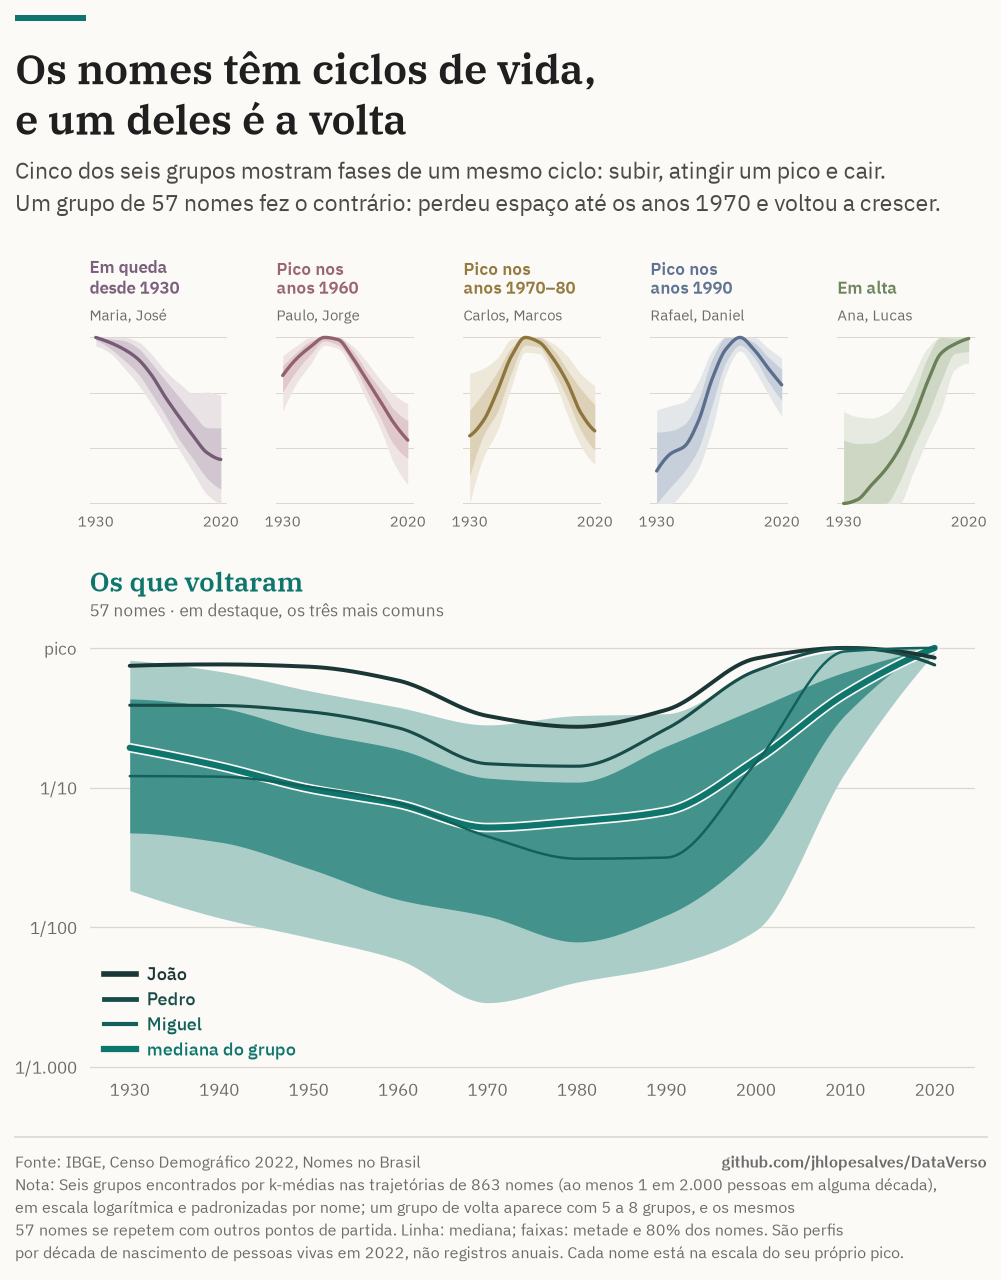

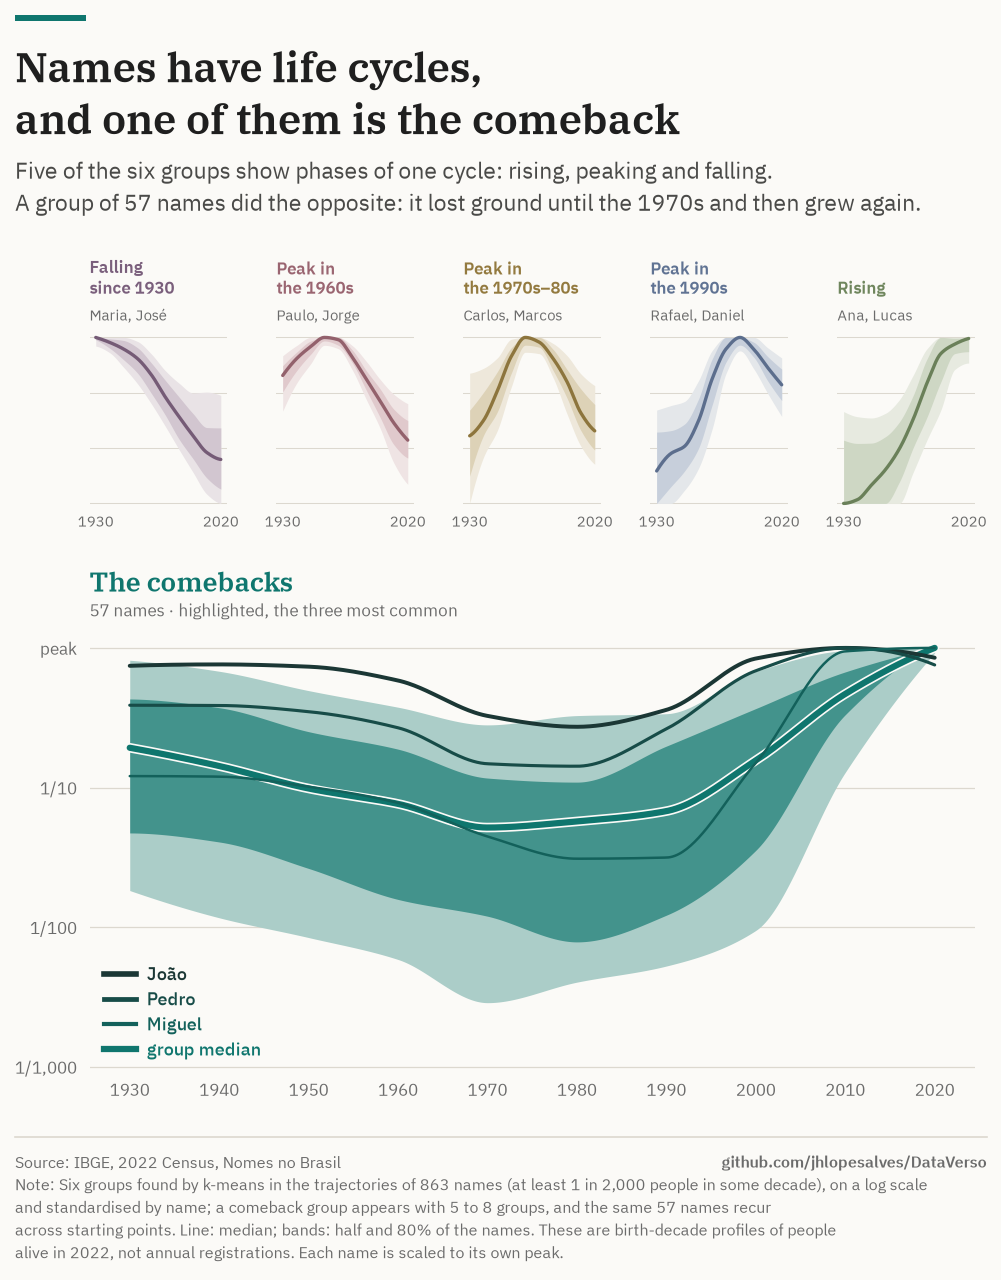

In [28]:
# Figure 3: five context groups and the comeback group, all on the same relative scale
cycles_for_figure = pd.read_csv(RESULTS_DIR / "life_cycles.csv").set_index("name")
group_ids = cycles_for_figure.pop("group")
post_names = ["alice", "helena", "cecilia", "joaquim", "aurora"]
for name, in_comeback in group_ids.reindex(post_names).eq(LIFE_CYCLE_K).items():
    print(f"{name}: {'yes' if in_comeback else 'no'} (comeback group)")

cycles_for_figure.columns = decades
profiles = cycles_for_figure.groupby(group_ids)
group_medians = profiles.median()
context_medians = group_medians.iloc[:-1]
comeback_median = group_medians.loc[LIFE_CYCLE_K]
context_peaks = context_medians.idxmax(axis="columns").tolist()
comeback_trough = comeback_median.idxmin()

if (
    context_peaks[:2] != [1930, 1960]
    or context_peaks[2] not in (1970, 1980)
    or context_peaks[3:] != [1990, 2020]
    or not context_medians.iloc[0].is_monotonic_decreasing
    or not context_medians.iloc[-1].is_monotonic_increasing
    or not 1970 <= comeback_trough <= 1990
    or not comeback_median.loc[1990:].is_monotonic_increasing
    or comeback_median.loc[2020] <= comeback_median.loc[1990]
):
    raise ValueError(
        f"Life-cycle copy needs review: peaks {context_peaks}, trough {comeback_trough}."
    )

robustness_for_figure = pd.read_csv(RESULTS_DIR / "life_cycle_robustness.csv")
resolutions = robustness_for_figure.query("comparison == 'resolution' and 5 <= k <= 8")
seed_checks = robustness_for_figure.query("comparison == 'seed'").set_index("seed")
if not (
    resolutions["k"].tolist() == list(range(5, 9))
    and resolutions["comeback_trough_decade"].between(1960, 1990).all()
    and resolutions["overlap_count"].gt(0).all()
):
    raise ValueError("The resolution checks do not support the life-cycle figure note.")

group_size = int(profiles.size().loc[LIFE_CYCLE_K])
if not (
    seed_checks.index.tolist() == list(range(10))
    and seed_zero_members.equals(main_members)
    and seed_checks["overlap_count"].eq(group_size).all()
):
    overlap_by_seed = seed_checks["overlap_count"].to_dict()
    raise ValueError(
        f"Seed checks need review. Main comeback group: {group_size} names. "
        f"Overlap with seed 0 by seed: {overlap_by_seed}."
    )

eligible_size = len(cycles_for_figure)
life_cycle_min_bearers = round(1 / LIFE_CYCLE_MIN_SHARE)
life_cycle_min_pt = f"{life_cycle_min_bearers:,}".replace(",", ".")
resolution_min, resolution_max = resolutions["k"].agg(["min", "max"])
LIFE_CYCLE_TEXT = {
    "pt": {
        "title": "Os nomes têm ciclos de vida,\ne um deles é a volta",
        "subtitle": (
            "Cinco dos seis grupos mostram fases de um mesmo ciclo: subir, atingir um pico e cair.\n"
            f"Um grupo de {group_size} nomes fez o contrário: perdeu espaço até os anos {comeback_trough} e voltou a crescer."
        ),
        "note": (
            f"Seis grupos encontrados por k-médias nas trajetórias de {eligible_size} nomes (ao menos 1 em {life_cycle_min_pt} pessoas em alguma década),\n"
            f"em escala logarítmica e padronizadas por nome; um grupo de volta aparece com {resolution_min} a {resolution_max} grupos, e os mesmos\n"
            f"{group_size} nomes se repetem com outros pontos de partida. Linha: mediana; faixas: metade e 80% dos nomes. São perfis\n"
            f"por década de nascimento de pessoas vivas em {REFERENCE_YEAR}, não registros anuais. Cada nome está na escala do seu próprio pico."
        ),
        "small_titles": (
            f"Em queda\ndesde {context_peaks[0]}",
            f"Pico nos\nanos {context_peaks[1]}",
            "Pico nos\nanos 1970–80",
            f"Pico nos\nanos {context_peaks[3]}",
            "Em alta",
        ),
        "big_title": "Os que voltaram",
        "caption": f"{group_size} nomes · em destaque, os três mais comuns",
        "median": "mediana do grupo",
        "ticks": ("pico", "1/10", "1/100", "1/1.000"),
    },
    "en": {
        "title": "Names have life cycles,\nand one of them is the comeback",
        "subtitle": (
            "Five of the six groups show phases of one cycle: rising, peaking and falling.\n"
            f"A group of {group_size} names did the opposite: it lost ground until the {comeback_trough}s and then grew again."
        ),
        "note": (
            f"Six groups found by k-means in the trajectories of {eligible_size} names (at least 1 in {life_cycle_min_bearers:,} people in some decade), on a log scale\n"
            f"and standardised by name; a comeback group appears with {resolution_min} to {resolution_max} groups, and the same {group_size} names recur\n"
            "across starting points. Line: median; bands: half and 80% of the names. These are birth-decade profiles of people\n"
            f"alive in {REFERENCE_YEAR}, not annual registrations. Each name is scaled to its own peak."
        ),
        "small_titles": (
            f"Falling\nsince {context_peaks[0]}",
            f"Peak in\nthe {context_peaks[1]}s",
            "Peak in\nthe 1970s–80s",
            f"Peak in\nthe {context_peaks[3]}s",
            "Rising",
        ),
        "big_title": "The comebacks",
        "caption": f"{group_size} names · highlighted, the three most common",
        "median": "group median",
        "ticks": ("peak", "1/10", "1/100", "1/1,000"),
    },
}


def smooth_profile(values):
    """Interpolate the ten decade values on the same fine grid as the waves."""
    return PchipInterpolator(x, np.asarray(values, dtype=float))(fine)


quantiles = profiles.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
# Match the prototype's context examples: sum the shares so each decade has equal weight.
example_scores = shares_by_name.loc[cycles_for_figure.index].sum(axis="columns")
comeback_examples = (
    names_total.loc[names_total["name"].isin(group_ids[group_ids == LIFE_CYCLE_K].index), "name"]
    .head(3)
    .tolist()
)
example_colours = [shade(ACCENT, amount) for amount in (0.72, 0.48, 0.24)]
example_widths = (1.9, 1.5, 1.2)
for lang in LANGUAGES:
    text = LIFE_CYCLE_TEXT[lang]
    fig = plt.figure(figsize=SOCIAL_SIZE, dpi=SOCIAL_DPI)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    grid = fig.add_gridspec(2, LIFE_CYCLE_K - 1, height_ratios=[1, 2.5], hspace=0.06, wspace=0.12)
    small_axes = [fig.add_subplot(grid[0, i]) for i in range(LIFE_CYCLE_K - 1)]
    big = fig.add_subplot(grid[1, :])

    for group, (ax, colour, title) in enumerate(
        zip(small_axes, GROUP_COLOURS, text["small_titles"], strict=True), start=1
    ):
        q = quantiles.loc[group]
        ax.fill_between(
            fine,
            smooth_profile(q.loc[0.10]),
            smooth_profile(q.loc[0.90]),
            color=tint(colour, 0.16),
            linewidth=0,
        )
        ax.fill_between(
            fine,
            smooth_profile(q.loc[0.25]),
            smooth_profile(q.loc[0.75]),
            color=tint(colour, 0.36),
            linewidth=0,
        )
        ax.plot(
            fine,
            smooth_profile(q.loc[0.50]),
            color=shade(colour, 0.2),
            linewidth=1.6,
            solid_capstyle="round",
        )
        examples = example_scores[group_ids == group].nlargest(2).index
        ax.set_title(
            title,
            loc="left",
            fontsize=8.4,
            fontweight="semibold",
            color=shade(colour, 0.15),
            pad=17,
            linespacing=1.1,
        )
        ax.text(
            0,
            1.03,
            ", ".join(DISPLAY_NAMES[name] for name in examples),
            transform=ax.transAxes,
            fontsize=7.2,
            color=MUTED,
            va="bottom",
        )
        ax.set_ylim(-3.05, 0.15)
        ax.yaxis.set_major_locator(FixedLocator([0, -1, -2, -3]))
        ax.grid(True, axis="y", color=RULE, linewidth=0.5)
        ax.tick_params(axis="y", labelleft=False)
        ax.set_xticks([x[0], x[-1]], [str(decades[0]), str(decades[-1])])
        ax.tick_params(axis="both", length=0, labelsize=7.4, labelcolor=MUTED)
        for spine in ax.spines.values():
            spine.set_visible(False)

    q = quantiles.loc[LIFE_CYCLE_K]
    big.fill_between(
        fine,
        smooth_profile(q.loc[0.10]),
        smooth_profile(q.loc[0.90]),
        color=tint(ACCENT, 0.34),
        linewidth=0,
        zorder=1,
    )
    big.fill_between(
        fine,
        smooth_profile(q.loc[0.25]),
        smooth_profile(q.loc[0.75]),
        color=tint(ACCENT, 0.78),
        linewidth=0,
        zorder=2,
    )
    big.plot(
        fine,
        smooth_profile(q.loc[0.50]),
        color=ACCENT,
        linewidth=3.0,
        zorder=4,
        solid_capstyle="round",
        path_effects=[patheffects.Stroke(linewidth=4.6, foreground=PAPER), patheffects.Normal()],
    )
    handles = []
    for name, colour, width in zip(comeback_examples, example_colours, example_widths, strict=True):
        big.plot(
            fine,
            smooth_profile(cycles_for_figure.loc[name]),
            color=colour,
            linewidth=width,
            zorder=5,
            solid_capstyle="round",
        )
        handles.append(Line2D([], [], color=colour, linewidth=width + 0.8))
    handles.append(Line2D([], [], color=ACCENT, linewidth=3.0))
    key = big.legend(
        handles,
        [*(DISPLAY_NAMES[name] for name in comeback_examples), text["median"]],
        loc="lower left",
        frameon=False,
        fontsize=8.6,
        handlelength=1.8,
        handletextpad=0.6,
        labelspacing=0.4,
        borderaxespad=0.4,
    )
    for label, colour in zip(key.get_texts(), [*example_colours, ACCENT], strict=True):
        label.set_color(colour)
        label.set_fontweight("medium")
    big.set_title(
        text["big_title"],
        loc="left",
        fontsize=13,
        fontweight="semibold",
        color=ACCENT,
        pad=19,
        fontfamily=TITLE_FONT,
    )
    big.text(
        0, 1.025, text["caption"], transform=big.transAxes, fontsize=8.2, color=MUTED, va="bottom"
    )
    big.set_ylim(-3.05, 0.12)
    big.set_yticks([0, -1, -2, -3], text["ticks"])
    big.grid(True, axis="y", color=RULE, linewidth=0.6, zorder=0)
    big.set_xticks(x, decades.astype(str))
    big.tick_params(axis="both", length=0, labelsize=8.4, labelcolor=MUTED)
    for spine in big.spines.values():
        spine.set_visible(False)
    fig.savefig(FIGURES_DIR / f"03_life_cycles_{lang}.png")
    plt.show()

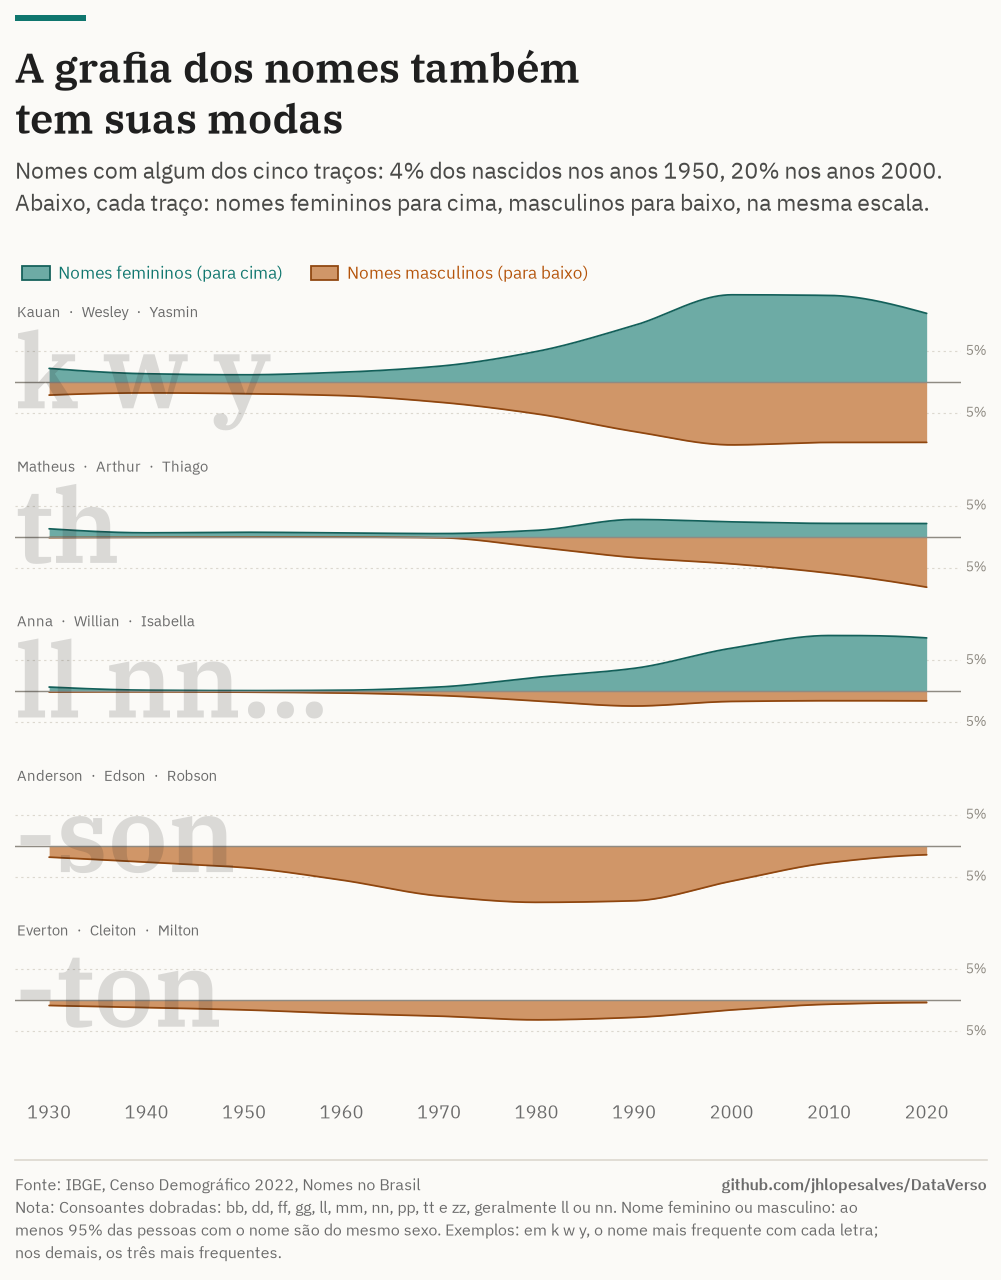

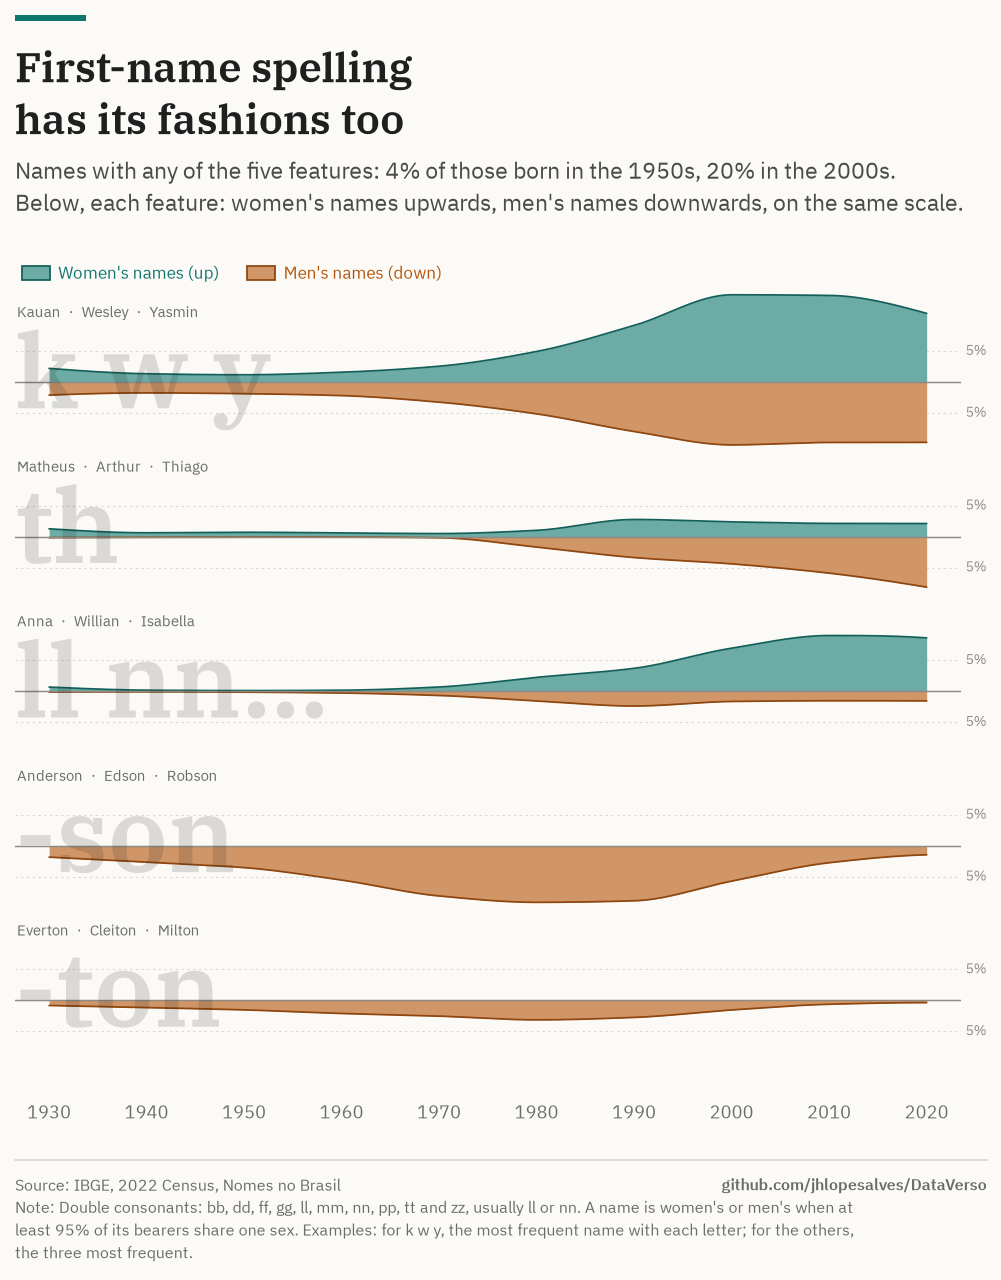

In [29]:
# Figure 4: the spelling patterns on a shared, mirrored scale
spelling_for_figure = pd.read_csv(RESULTS_DIR / "spelling_by_decade.csv")
spelling_shares = spelling_for_figure.pivot(
    index="decade", columns=["pattern", "sex_class"], values="share"
)
a1950, a2000 = (f"{spelling_shares.loc[d, ('any', 'all')]:.0%}" for d in (1950, 2000))

double_people = spelling_for_figure.query("pattern == 'double_consonant' and sex_class == 'all'")
ll_nn_people = (
    names_decade[names_decade["name"].str.contains(r"ll|nn")].groupby("decade")["count"].sum()
)
ll_nn_share = ll_nn_people / double_people.set_index("decade")["people"]
mostly_ll_nn = ll_nn_share.loc[1980:].ge(0.95).all()

glyphs = ("k w y", "th", "ll nn…", "-son", "-ton")
examples = {
    "kwy": [
        names_total.loc[names_total["name"].str.contains(letter, regex=False), "name"].iloc[0]
        for letter in "kwy"
    ],
    **{
        pattern: names_total.loc[pattern_flags[pattern], "name"].head(3).tolist()
        for pattern in SPELLING_PATTERNS
        if pattern != "kwy"
    },
}
for pattern, names in examples.items():
    letters = tuple("kwy") if pattern == "kwy" else (SPELLING_PATTERNS[pattern],) * len(names)
    if any(
        re.search(regex, DISPLAY_NAMES[name].casefold()) is None
        for regex, name in zip(letters, names, strict=True)
    ):
        raise ValueError(f"A displayed example for {pattern} lacks its spelling feature.")

ll_nn_pt = "quase sempre ll ou nn" if mostly_ll_nn else "geralmente ll ou nn"
ll_nn_en = "almost always ll or nn" if mostly_ll_nn else "usually ll or nn"
SPELLING_TEXT = {
    "pt": {
        "title": "A grafia dos nomes também\ntem suas modas",
        "subtitle": (
            f"Nomes com algum dos cinco traços: {a1950} dos nascidos nos anos 1950, {a2000} nos anos 2000.\n"
            "Abaixo, cada traço: nomes femininos para cima, masculinos para baixo, na mesma escala."
        ),
        "note": (
            f"Consoantes dobradas: bb, dd, ff, gg, ll, mm, nn, pp, tt e zz, {ll_nn_pt}. Nome feminino ou masculino: ao\n"
            f"menos {sex_cutoff} das pessoas com o nome são do mesmo sexo. Exemplos: em k w y, o nome mais frequente com cada letra;\n"
            "nos demais, os três mais frequentes."
        ),
        "legend": ("Nomes femininos (para cima)", "Nomes masculinos (para baixo)"),
    },
    "en": {
        "title": "First-name spelling\nhas its fashions too",
        "subtitle": (
            f"Names with any of the five features: {a1950} of those born in the 1950s, {a2000} in the 2000s.\n"
            "Below, each feature: women's names upwards, men's names downwards, on the same scale."
        ),
        "note": (
            f"Double consonants: bb, dd, ff, gg, ll, mm, nn, pp, tt and zz, {ll_nn_en}. A name is women's or men's when at\n"
            f"least {sex_cutoff} of its bearers share one sex. Examples: for k w y, the most frequent name with each letter; for the others,\n"
            "the three most frequent."
        ),
        "legend": ("Women's names (up)", "Men's names (down)"),
    },
}

spelling_fine = np.linspace(x[0], x[-1], 600)
scale = 0.6 / 0.15  # A share of 15% spans 0.6 rows, in either direction.
guide_share = 0.05
n_rows = len(SPELLING_PATTERNS)
for lang in LANGUAGES:
    text = SPELLING_TEXT[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE, dpi=SOCIAL_DPI)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    for row, (pattern, glyph) in enumerate(zip(SPELLING_PATTERNS, glyphs, strict=True)):
        mid = n_rows - 1 - row
        ax.text(
            -0.35,
            mid - 0.17,
            glyph,
            ha="left",
            va="baseline",
            fontsize=50,
            fontfamily=TITLE_FONT,
            fontweight="semibold",
            color=INK,
            alpha=0.15,
            zorder=5,
        )
        ax.text(
            -0.33,
            mid + 0.42,
            "  ·  ".join(DISPLAY_NAMES[name] for name in examples[pattern]),
            ha="left",
            va="baseline",
            fontsize=7.4,
            color=MUTED,
            zorder=6,
        )
        for sign, (sex, colour) in zip((1, -1), SEX_COLOURS.items(), strict=True):
            guide = mid + sign * guide_share * scale
            ax.plot(
                [-0.35, 9.35],
                [guide, guide],
                color=RULE,
                linewidth=0.55,
                linestyle=(0, (2, 3)),
                zorder=1,
            )
            ax.text(
                9.4,
                guide,
                f"{guide_share:.0%}",
                ha="left",
                va="center",
                fontsize=6.6,
                color=AXIS,
                clip_on=False,
            )
            values = spelling_shares.loc[decades, (pattern, sex)].to_numpy()
            curve = np.clip(PchipInterpolator(x, values)(spelling_fine), 0, None) * scale * sign
            ax.fill_between(
                spelling_fine, mid, mid + curve, color=tint(colour, 0.6), linewidth=0, zorder=3
            )
            if values.any():
                ax.plot(
                    spelling_fine,
                    mid + curve,
                    color=shade(colour, 0.25),
                    linewidth=0.85,
                    zorder=4,
                    solid_capstyle="round",
                )
        ax.plot([-0.35, 9.35], [mid, mid], color=AXIS, linewidth=0.7, zorder=4)

    key = ax.legend(
        handles=[
            Patch(facecolor=tint(colour, 0.6), edgecolor=shade(colour, 0.25), linewidth=0.85)
            for colour in SEX_COLOURS.values()
        ],
        labels=text["legend"],
        loc="upper left",
        bbox_to_anchor=(0, 1),
        ncol=2,
        frameon=False,
        fontsize=8.3,
        handlelength=1.6,
        handleheight=0.9,
        columnspacing=1.6,
        borderaxespad=0,
        handletextpad=0.5,
    )
    for label, colour in zip(key.get_texts(), SEX_COLOURS.values(), strict=True):
        label.set_color(colour)
    ax.set_xticks(x, decades.astype(str))
    ax.tick_params(axis="x", length=0, labelsize=8.5, labelcolor=MUTED, pad=4)
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xlim(-0.35, 9.35)
    ax.set_ylim(-0.62, n_rows - 1 + 0.8)
    fig.savefig(FIGURES_DIR / f"04_spelling_{lang}.png")
    plt.show()